# Module 07d: Pandas Time Series Analysis

## Why Time Series?

Time series data is everywhere in the real world:
- **Finance**: Stock prices, cryptocurrency values, trading volumes
- **Retail**: Daily sales, seasonal demand patterns
- **Weather**: Temperature, rainfall, humidity over time
- **IoT/Sensors**: Equipment readings, energy consumption
- **Healthcare**: Patient vitals, disease spread tracking
- **Web Analytics**: Website traffic, user engagement metrics

Pandas provides **powerful tools** specifically designed for time series data, making operations like:
- Parsing dates and times from strings
- Resampling data (daily → weekly, hourly → daily)
- Handling missing time periods
- Computing rolling statistics (moving averages)
- Time-based indexing and slicing

...incredibly easy!

---

## What You'll Learn

| Section | Topic | Duration |
|---------|-------|----------|
| 1 | [DateTime Basics](#1.-DateTime-Basics) | 20 min |
| 2 | [Creating Time Series Data](#2.-Creating-Time-Series-Data) | 25 min |
| 3 | [Time-Based Indexing & Selection](#3.-Time-Based-Indexing-and-Selection) | 20 min |
| 4 | [Resampling & Frequency Conversion](#4.-Resampling-and-Frequency-Conversion) | 30 min |
| 5 | [Rolling Windows & Moving Statistics](#5.-Rolling-Windows-and-Moving-Statistics) | 25 min |
| 6 | [Handling Missing Data in Time Series](#6.-Handling-Missing-Data-in-Time-Series) | 20 min |
| 7 | [Time Zones](#7.-Time-Zones) | 15 min |
| 8 | [Case Study: E-Commerce Analytics](#8.-Case-Study-E-Commerce-Analytics) | 30 min |
| 9 | [Live Exercises with Solutions](#9.-Live-Exercises-with-Solutions) | 35 min |

**Total Estimated Time: ~3.5 hours**

---

## Setup

In [1]:
# =============================================================================
# SETUP: Import required libraries for time series analysis
# =============================================================================

# Import pandas - the primary library for data manipulation and time series
# pd is the standard alias used throughout the data science community
import pandas as pd

# Import numpy - provides numerical operations and array handling
# np is the standard alias; we'll use it for random data generation
import numpy as np

# Import matplotlib for creating visualizations of time series data
# plt is the standard alias for the pyplot interface
import matplotlib.pyplot as plt

# Import Python's built-in datetime module for additional date/time operations
# datetime: creates datetime objects, timedelta: represents duration between times
from datetime import datetime, timedelta

# Import warnings module to suppress unnecessary warning messages
import warnings
# filterwarnings('ignore') hides warnings that can clutter output during teaching
# Note: In production code, you'd want to handle warnings appropriately
warnings.filterwarnings('ignore')

# =============================================================================
# DISPLAY SETTINGS: Configure how pandas shows data in output
# =============================================================================

# Set maximum columns to display - prevents wide DataFrames from being truncated
# 15 columns is a reasonable default for most screens
pd.set_option('display.max_columns', 15)

# Set display width in characters - controls line wrapping in output
# 200 characters allows wider DataFrames to display without wrapping
pd.set_option('display.width', 200)

# Set matplotlib style for cleaner, professional-looking charts
# 'seaborn-v0_8-whitegrid' provides a clean white background with grid lines
plt.style.use('seaborn-v0_8-whitegrid')

# Print version info to verify successful imports
# Useful for debugging version-specific issues
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("\n✓ Setup complete!")

Pandas version: 2.3.3
NumPy version: 2.3.5

✓ Setup complete!


---

# 1. DateTime Basics

Before diving into time series analysis, we need to understand how Pandas handles dates and times.

## Key DateTime Types in Pandas

| Type | Description | Example |
|------|-------------|--------|
| `Timestamp` | Single moment in time | `2024-01-15 09:30:00` |
| `DatetimeIndex` | Index of Timestamps | Index for time series |
| `Period` | A span of time | January 2024, Q1 2024 |
| `Timedelta` | Duration between times | 5 days, 3 hours |

## Creating Timestamps

In [2]:
# =============================================================================
# CREATING TIMESTAMPS: pd.Timestamp is pandas' representation of a single moment
# A Timestamp is similar to Python's datetime but with nanosecond precision
# =============================================================================

# METHOD 1: Create Timestamp from a string (most common in practice)
# pd.Timestamp() automatically parses common date string formats
# When no time is specified, it defaults to midnight (00:00:00)
ts1 = pd.Timestamp('2024-01-15')
print("From string:", ts1)

# METHOD 2: Create Timestamp with both date AND time included
# Format: 'YYYY-MM-DD HH:MM:SS' (ISO 8601 format)
# Pandas recognizes spaces, 'T', or other separators between date and time
ts2 = pd.Timestamp('2024-01-15 09:30:00')
print("With time:", ts2)

# METHOD 3: Create Timestamp from individual components (explicit control)
# Use keyword arguments: year, month, day, hour, minute, second, microsecond
# Useful when you have date parts stored in separate variables
ts3 = pd.Timestamp(year=2024, month=1, day=15, hour=9, minute=30)
print("From components:", ts3)

# METHOD 4: Get the current system time as a Timestamp
# pd.Timestamp.now() returns the current local time
# Alternative: pd.Timestamp.utcnow() for UTC time
ts_now = pd.Timestamp.now()
print("Current time:", ts_now)

From string: 2024-01-15 00:00:00
With time: 2024-01-15 09:30:00
From components: 2024-01-15 09:30:00
Current time: 2026-01-30 21:29:05.516433


In [3]:
# =============================================================================
# EXTRACTING COMPONENTS: Access individual parts of a Timestamp
# These attributes are essential for grouping, filtering, and feature engineering
# =============================================================================

# Create a sample Timestamp with date and time
ts = pd.Timestamp('2024-03-15 14:30:45')

# Display the full timestamp
print(f"Full timestamp: {ts}")

# .year - Extract the 4-digit year (integer)
print(f"Year: {ts.year}")

# .month - Extract the month number (1-12, integer)
print(f"Month: {ts.month}")

# .day - Extract the day of month (1-31, integer)
print(f"Day: {ts.day}")

# .hour - Extract the hour (0-23, integer, 24-hour format)
print(f"Hour: {ts.hour}")

# .minute - Extract the minute (0-59, integer)
print(f"Minute: {ts.minute}")

# .second - Extract the second (0-59, integer)
print(f"Second: {ts.second}")

# .dayofweek - Day of week as integer (IMPORTANT: 0=Monday, 6=Sunday)
# This is 0-indexed! Common source of bugs for students
print(f"Day of week: {ts.dayofweek}")  # 0=Monday, 6=Sunday

# .day_name() - Returns the full name of the day as a string
# Note: This is a METHOD (needs parentheses), not a property
print(f"Day name: {ts.day_name()}")

# .month_name() - Returns the full name of the month as a string
print(f"Month name: {ts.month_name()}")

# .isocalendar().week - ISO week number (1-52/53)
# Uses ISO 8601 standard where week 1 contains the first Thursday of the year
print(f"Week of year: {ts.isocalendar().week}")

# .quarter - Returns the quarter (1, 2, 3, or 4)
# Q1=Jan-Mar, Q2=Apr-Jun, Q3=Jul-Sep, Q4=Oct-Dec
print(f"Quarter: {ts.quarter}")

Full timestamp: 2024-03-15 14:30:45
Year: 2024
Month: 3
Day: 15
Hour: 14
Minute: 30
Second: 45
Day of week: 4
Day name: Friday
Month name: March
Week of year: 11
Quarter: 1


## Converting Strings to DateTime with `pd.to_datetime()`

In real data, dates come in many formats. `pd.to_datetime()` is your Swiss Army knife for parsing them.

In [4]:
# =============================================================================
# pd.to_datetime(): The Swiss Army Knife for Date Parsing
# Automatically detects and parses many common date string formats
# Returns a Timestamp (single value) or DatetimeIndex (for arrays/Series)
# =============================================================================

# Create a list of date strings in various formats
# pd.to_datetime() will attempt to parse each one automatically
dates = [
    '2024-01-15',           # ISO format (YYYY-MM-DD) - universally recognized
    '01/15/2024',           # US format (MM/DD/YYYY)
    '15-01-2024',           # EU format (DD-MM-YYYY) - day first
    'January 15, 2024',     # Written out with full month name
    '2024/01/15 09:30:00',  # With time included
]

# Loop through each date string and parse it
for date_str in dates:
    # pd.to_datetime() parameters:
    # - First arg: the string (or array/Series) to parse
    # - dayfirst=False: assume month comes before day (US convention)
    # - dayfirst=True: assume day comes before month (EU convention)
    # TIP: When parsing EU format dates, set dayfirst=True
    parsed = pd.to_datetime(date_str, dayfirst=False)  # dayfirst=True for EU format
    print(f"'{date_str}' -> {parsed}")

'2024-01-15' -> 2024-01-15 00:00:00
'01/15/2024' -> 2024-01-15 00:00:00
'15-01-2024' -> 2024-01-15 00:00:00
'January 15, 2024' -> 2024-01-15 00:00:00
'2024/01/15 09:30:00' -> 2024-01-15 09:30:00


In [ ]:
# =============================================================================
# CUSTOM FORMAT PARSING: Use 'format' parameter for non-standard date strings
# When automatic parsing fails or is ambiguous, specify the exact format
# =============================================================================

# STRFTIME FORMAT CODES REFERENCE (memorize these!):
# %Y = 4-digit year (2024)      %y = 2-digit year (24)
# %m = month as number (01-12)  %d = day of month (01-31)
# %H = hour 24-hr format (00-23) %I = hour 12-hr format (01-12)
# %M = minute (00-59)           %S = second (00-59)
# %f = microsecond (000000-999999)
# %B = full month name (January)  %b = abbreviated month (Jan)
# %A = full day name (Monday)     %a = abbreviated day (Mon)
# %p = AM/PM indicator

# EXAMPLE 1: Parse a non-standard format from web server logs
# Format: DD/Mon/YYYY:HH:MM:SS (common Apache log format)
custom_date = '15/Mar/2024:09:30:45'

# Build the format string to match the input exactly:
# %d = day (15), %b = abbreviated month (Mar), %Y = year (2024)
# The / and : characters are literal separators that must match
parsed = pd.to_datetime(custom_date, format='%d/%b/%Y:%H:%M:%S')
print(f"Custom format parsed: {parsed}")

# EXAMPLE 2: ISO 8601 format with 'T' separator and microseconds
# This is the international standard format, often used in APIs and logs
# Pandas auto-detects this format - no format string needed
log_date = '2024-01-15T09:30:45.123456'
parsed = pd.to_datetime(log_date)
print(f"ISO format with microseconds: {parsed}")

## Timedelta - Working with Durations

In [ ]:
# =============================================================================
# TIMEDELTA: Represents a duration or difference between two timestamps
# Essential for date arithmetic: adding/subtracting time from dates
# =============================================================================

# METHOD 1: Create Timedelta using keyword arguments
# Specify the duration with named parameters for clarity
delta1 = pd.Timedelta(days=5)

# METHOD 2: Combine multiple time units in one Timedelta
# You can mix days, hours, minutes, seconds, milliseconds, microseconds
delta2 = pd.Timedelta(hours=3, minutes=30)

# METHOD 3: Create Timedelta from a human-readable string
# Pandas parses natural language duration strings
delta3 = pd.Timedelta('2 days 5 hours 30 minutes')

print("5 days:", delta1)
print("3h 30m:", delta2)
print("From string:", delta3)

# =============================================================================
# DATE ARITHMETIC: Add or subtract Timedeltas from Timestamps
# =============================================================================

# Get current timestamp
today = pd.Timestamp.now()

# Add a week (7 days) to get next week's date
# Timedelta + Timestamp = Timestamp (shifted forward in time)
next_week = today + pd.Timedelta(weeks=1)

print(f"\nToday: {today.date()}")
print(f"Next week: {next_week.date()}")

# =============================================================================
# CALCULATING DIFFERENCES: Subtracting Timestamps yields a Timedelta
# =============================================================================

# Create two timestamps
start = pd.Timestamp('2024-01-01')
end = pd.Timestamp('2024-03-15')

# Timestamp - Timestamp = Timedelta (the duration between them)
diff = end - start
print(f"\nDifference: {diff}")

# .days attribute extracts just the number of whole days
# Useful when you need an integer for calculations
print(f"In days: {diff.days}")

### 💡 Instructor Note

**Common pitfall**: Students often forget that `dayofweek` is 0-indexed (Monday=0). Ask them: "What day is `dayofweek=4`?" (Answer: Friday)

---

# 2. Creating Time Series Data

Let's create realistic simulated data that mimics real-world scenarios.

## Using `pd.date_range()` - Generate Date Sequences

This is the primary way to create datetime indices.

In [ ]:
# =============================================================================
# pd.date_range(): Generate sequences of dates at regular intervals
# This is the PRIMARY way to create DatetimeIndex for time series analysis
# =============================================================================

# Create a basic date range from start to end date
# Parameters:
#   start: beginning date (string or Timestamp)
#   end: ending date (string or Timestamp)
#   freq: frequency (default 'D' for daily) - see frequency codes reference
# Returns: DatetimeIndex (array-like container of Timestamps)
dates_daily = pd.date_range(start='2024-01-01', end='2024-01-10')

print("Daily (default):")
print(dates_daily)

# DatetimeIndex is the index type used for time series DataFrames
# It enables powerful time-based slicing and resampling operations
print(f"Type: {type(dates_daily)}")

In [5]:
# =============================================================================
# FREQUENCY CODES: Control the interval between generated dates
# Use 'periods' parameter to specify count instead of end date
# =============================================================================

print("\n=== Common Frequency Codes ===")

# HOURLY: freq='H' generates timestamps at each hour
# 'periods=6' creates exactly 6 timestamps starting from the start date
hourly = pd.date_range('2024-01-01', periods=6, freq='H')
print(f"\nHourly (H): {list(hourly)}")

# BUSINESS DAYS: freq='B' skips weekends (Saturday and Sunday)
# Notice: Jan 6-7 2024 are weekend, so jumps to Jan 8
business = pd.date_range('2024-01-01', periods=6, freq='B')
print(f"\nBusiness days (B): {list(business)}")

# WEEKLY: freq='W' generates weekly dates (default anchor: Sunday)
# Use 'W-MON' for Monday, 'W-FRI' for Friday anchoring
weekly = pd.date_range('2024-01-01', periods=4, freq='W')
print(f"\nWeekly (W): {list(weekly)}")

# MONTH END: freq='ME' generates last day of each month
# Automatically handles varying month lengths (28, 29, 30, 31 days)
# Note: Older pandas used 'M', newer versions use 'ME'
monthly = pd.date_range('2024-01-01', periods=4, freq='ME')
print(f"\nMonth End (ME): {list(monthly)}")

# MONTH START: freq='MS' generates first day of each month
# Useful for monthly reporting periods
monthly_start = pd.date_range('2024-01-01', periods=4, freq='MS')
print(f"\nMonth Start (MS): {list(monthly_start)}")

# QUARTER END: freq='QE' generates last day of each quarter
# Q1=Mar 31, Q2=Jun 30, Q3=Sep 30, Q4=Dec 31
# Note: Older pandas used 'Q', newer versions use 'QE'
quarterly = pd.date_range('2024-01-01', periods=4, freq='QE')
print(f"\nQuarter End (QE): {list(quarterly)}")


=== Common Frequency Codes ===

Hourly (H): [Timestamp('2024-01-01 00:00:00'), Timestamp('2024-01-01 01:00:00'), Timestamp('2024-01-01 02:00:00'), Timestamp('2024-01-01 03:00:00'), Timestamp('2024-01-01 04:00:00'), Timestamp('2024-01-01 05:00:00')]

Business days (B): [Timestamp('2024-01-01 00:00:00'), Timestamp('2024-01-02 00:00:00'), Timestamp('2024-01-03 00:00:00'), Timestamp('2024-01-04 00:00:00'), Timestamp('2024-01-05 00:00:00'), Timestamp('2024-01-08 00:00:00')]

Weekly (W): [Timestamp('2024-01-07 00:00:00'), Timestamp('2024-01-14 00:00:00'), Timestamp('2024-01-21 00:00:00'), Timestamp('2024-01-28 00:00:00')]

Month End (ME): [Timestamp('2024-01-31 00:00:00'), Timestamp('2024-02-29 00:00:00'), Timestamp('2024-03-31 00:00:00'), Timestamp('2024-04-30 00:00:00')]

Month Start (MS): [Timestamp('2024-01-01 00:00:00'), Timestamp('2024-02-01 00:00:00'), Timestamp('2024-03-01 00:00:00'), Timestamp('2024-04-01 00:00:00')]

Quarter End (QE): [Timestamp('2024-03-31 00:00:00'), Timestamp('

### Frequency Codes Reference

| Code | Description |
|------|-------------|
| `D` | Calendar day |
| `B` | Business day |
| `W` | Weekly |
| `ME` | Month end |
| `MS` | Month start |
| `QE` | Quarter end |
| `YE` | Year end |
| `H` | Hourly |
| `T` or `min` | Minute |
| `S` | Second |
| `2H` | Every 2 hours |
| `3D` | Every 3 days |

## 📊 Creating Simulated Real-World Data

Let's create a realistic e-commerce sales dataset that we'll use throughout this module.

### Scenario: Online Retail Store
We'll simulate 2 years of daily sales data with:
- **Trend**: Gradual growth over time (business expansion)
- **Seasonality**: Higher sales during holidays, weekends
- **Weekly patterns**: Lower sales on Mondays, higher on weekends
- **Random noise**: Day-to-day variations
- **Special events**: Black Friday, Christmas spikes

In [43]:
# =============================================================================
# PREPARING TO CREATE SIMULATED E-COMMERCE DATA
# We'll generate 2 years of daily sales data for teaching purposes
# =============================================================================

# Set random seed for reproducibility
# np.random.seed(42) ensures everyone gets the SAME random values
# This is crucial for teaching - students can reproduce your exact results
# The number 42 is arbitrary (Douglas Adams reference!), any integer works
np.random.seed(42)

# Create date range for 2 years of daily data
# start: first date in the sequence
# end: last date in the sequence (inclusive)
# freq='D': daily frequency (one timestamp per calendar day)
dates = pd.date_range(start='2023-01-01', end='2024-12-31', freq='D')

# Store the count of days for later calculations
n_days = len(dates)

# Verify our date range
# .date() converts Timestamp to Python date object for cleaner printing
print(f"Date range: {dates[0].date()} to {dates[-1].date()}")
print(f"Total days: {n_days}")

Date range: 2023-01-01 to 2024-12-31
Total days: 731


In [ ]:
# =============================================================================
# DATA GENERATION FUNCTION: Creates realistic e-commerce sales patterns
# This function demonstrates how real time series data has multiple components
# =============================================================================

def create_ecommerce_sales_data(dates):
    """
    Create realistic e-commerce sales data with multiple patterns.
    
    Components:
    1. Base sales level (~$10,000/day)
    2. Growth trend (15% annual growth)
    3. Yearly seasonality (holiday peaks)
    4. Weekly seasonality (weekend boost)
    5. Special events (Black Friday, Christmas)
    6. Random noise
    """
    # Get the number of days we need to generate
    n = len(dates)
    
    # COMPONENT 1: BASE LEVEL
    # Starting point for daily sales - represents typical daily revenue
    base = 10000
    
    # COMPONENT 2: GROWTH TREND
    # Simulate business growth: 15% annual = compounding daily growth
    # Formula: daily_rate = (1 + annual_rate)^(1/365)
    # This creates an exponential curve over time
    daily_growth = 1.15 ** (1/365)  # Daily multiplier for 15% annual
    # Apply compound growth: base * growth_rate^day_number
    trend = base * np.array([daily_growth ** i for i in range(n)])
    
    # COMPONENT 3: YEARLY SEASONALITY
    # Use sine wave to create annual pattern with peaks in holiday season
    # dayofyear: 1-365 representing position in the year
    day_of_year = np.array([d.dayofyear for d in dates])
    # Sine wave shifted so peak (~1.0) occurs around late November (day 330)
    # 0.2 amplitude means ±20% variation from the trend
    yearly_seasonal = 0.2 * np.sin(2 * np.pi * (day_of_year - 60) / 365)
    
    # COMPONENT 4: WEEKLY SEASONALITY
    # Different sales patterns by day of week (common in retail)
    # dayofweek: 0=Monday through 6=Sunday
    day_of_week = np.array([d.dayofweek for d in dates])
    # Dictionary maps day number to percentage adjustment
    weekly_pattern = {
        0: -0.15,  # Monday (slowest) - 15% below average
        1: -0.08,  # Tuesday
        2: -0.03,  # Wednesday
        3: 0.02,   # Thursday
        4: 0.10,   # Friday - TGIF shopping
        5: 0.12,   # Saturday (highest) - peak shopping day
        6: 0.08    # Sunday
    }
    # Convert day numbers to their adjustment factors
    weekly_seasonal = np.array([weekly_pattern[d] for d in day_of_week])
    
    # COMPONENT 5: SPECIAL EVENTS
    # One-time or annual spikes that override normal patterns
    special_events = np.zeros(n)  # Start with zero effect
    for i, date in enumerate(dates):
        # Black Friday (4th Friday of November) - biggest shopping day
        if date.month == 11 and date.day >= 22 and date.day <= 28 and date.dayofweek == 4:
            special_events[i] = 1.5  # 150% boost (2.5x normal)
        # Black Friday weekend - extended sale period
        elif date.month == 11 and date.day >= 23 and date.day <= 30:
            special_events[i] = 0.5  # 50% boost
        # Christmas shopping week - gift buying surge
        elif date.month == 12 and date.day >= 15 and date.day <= 24:
            special_events[i] = 0.7  # 70% boost
        # Post-Christmas slump - everyone is spent!
        elif date.month == 12 and date.day >= 26:
            special_events[i] = -0.3  # 30% decrease
        # Valentine's Day week
        elif date.month == 2 and date.day >= 7 and date.day <= 14:
            special_events[i] = 0.25
        # Back to school (August)
        elif date.month == 8:
            special_events[i] = 0.15
    
    # COMPONENT 6: RANDOM NOISE
    # Real data has unpredictable day-to-day variation
    # Normal distribution with mean=0, std=0.08 (±8% typical variation)
    noise = np.random.normal(0, 0.08, n)
    
    # COMBINE ALL COMPONENTS
    # Multiply trend by (1 + all_adjustments) to get final sales
    # This is a multiplicative model: components scale the trend
    sales = trend * (1 + yearly_seasonal + weekly_seasonal + special_events + noise)
    
    # ENSURE NON-NEGATIVE: Sales can't be negative in real world
    # np.maximum compares element-wise, keeps larger value
    sales = np.maximum(sales, 0)
    
    return sales

# =============================================================================
# CREATE THE DATAFRAME: Our main dataset for the tutorial
# =============================================================================

# Call our function to generate the sales values
sales = create_ecommerce_sales_data(dates)

# Create DataFrame with date and sales columns
# This is a common pattern: DatetimeIndex as column initially, then set as index
df_sales = pd.DataFrame({
    'date': dates,           # The DatetimeIndex we created earlier
    'sales': sales.round(2)  # Round to 2 decimal places (dollars and cents)
})

# =============================================================================
# FEATURE ENGINEERING: Add derived datetime columns using .dt accessor
# The .dt accessor provides access to datetime properties on a Series
# =============================================================================

# .dt.year - Extract the year (2023 or 2024 in our data)
df_sales['year'] = df_sales['date'].dt.year

# .dt.month - Extract month number (1-12)
df_sales['month'] = df_sales['date'].dt.month

# .dt.dayofweek - Day of week as integer (0=Monday, 6=Sunday)
df_sales['day_of_week'] = df_sales['date'].dt.dayofweek

# .dt.day_name() - Human-readable day name ('Monday', 'Tuesday', etc.)
# Note: This is a METHOD (with parentheses), not a property
df_sales['day_name'] = df_sales['date'].dt.day_name()

# Create boolean column for weekend detection
# .isin([5, 6]) returns True for Saturday (5) and Sunday (6)
df_sales['is_weekend'] = df_sales['day_of_week'].isin([5, 6])

print("E-Commerce Sales Dataset Created!")
print("="*50)
# Display first 10 rows to verify the data
df_sales.head(10)
df_sales.to_csv('ecom_sales.csv',index=False)

E-Commerce Sales Dataset Created!


,date,sales,year,month,day_of_week,day_name,is_weekend
0,2023-01-01,9497.74,2023,1,6,Sunday,True
1,2023-01-02,6710.72,2023,1,0,Monday,False
2,2023-01-03,8061.98,2023,1,1,Tuesday,False
3,2023-01-04,9286.13,2023,1,2,Wednesday,False
4,2023-01-05,8402.46,2023,1,3,Thursday,False
5,2023-01-06,9227.62,2023,1,4,Friday,False
6,2023-01-07,10906.51,2023,1,5,Saturday,True
7,2023-01-08,9879.80,2023,1,6,Sunday,True
8,2023-01-09,6605.80,2023,1,0,Monday,False
9,2023-01-10,8145.46,2023,1,1,Tuesday,False


In [47]:
df = pd.read_csv('../../00-data/ecom_sales.csv')

In [48]:
# =============================================================================
# QUICK STATISTICS: Verify our dataset and understand its distribution
# These are common first steps when exploring any time series dataset
# =============================================================================

print("Dataset Summary:")

# .min() and .max() on datetime column give the date range
# .date() converts Timestamp to date for cleaner display
print(f"Date range: {df_sales['date'].min().date()} to {df_sales['date'].max().date()}")

# len() gives row count; :, in f-string adds thousand separators
print(f"Total records: {len(df_sales):,}")

print(f"\nSales Statistics:")

# .sum() - Total of all daily sales over 2 years
# :,.2f format: comma separators, 2 decimal places
print(f"  Total Sales: ${df_sales['sales'].sum():,.2f}")

# .mean() - Average daily sales (useful baseline metric)
print(f"  Daily Average: ${df_sales['sales'].mean():,.2f}")

# .min() - Lowest sales day (identify worst performers)
print(f"  Min Daily Sales: ${df_sales['sales'].min():,.2f}")

# .max() - Highest sales day (likely Black Friday or Christmas!)
print(f"  Max Daily Sales: ${df_sales['sales'].max():,.2f}")

Dataset Summary:
Date range: 2023-01-01 to 2024-12-31
Total records: 731

Sales Statistics:
  Total Sales: $8,958,999.50
  Daily Average: $12,255.81
  Min Daily Sales: $4,656.43
  Max Daily Sales: $30,906.71


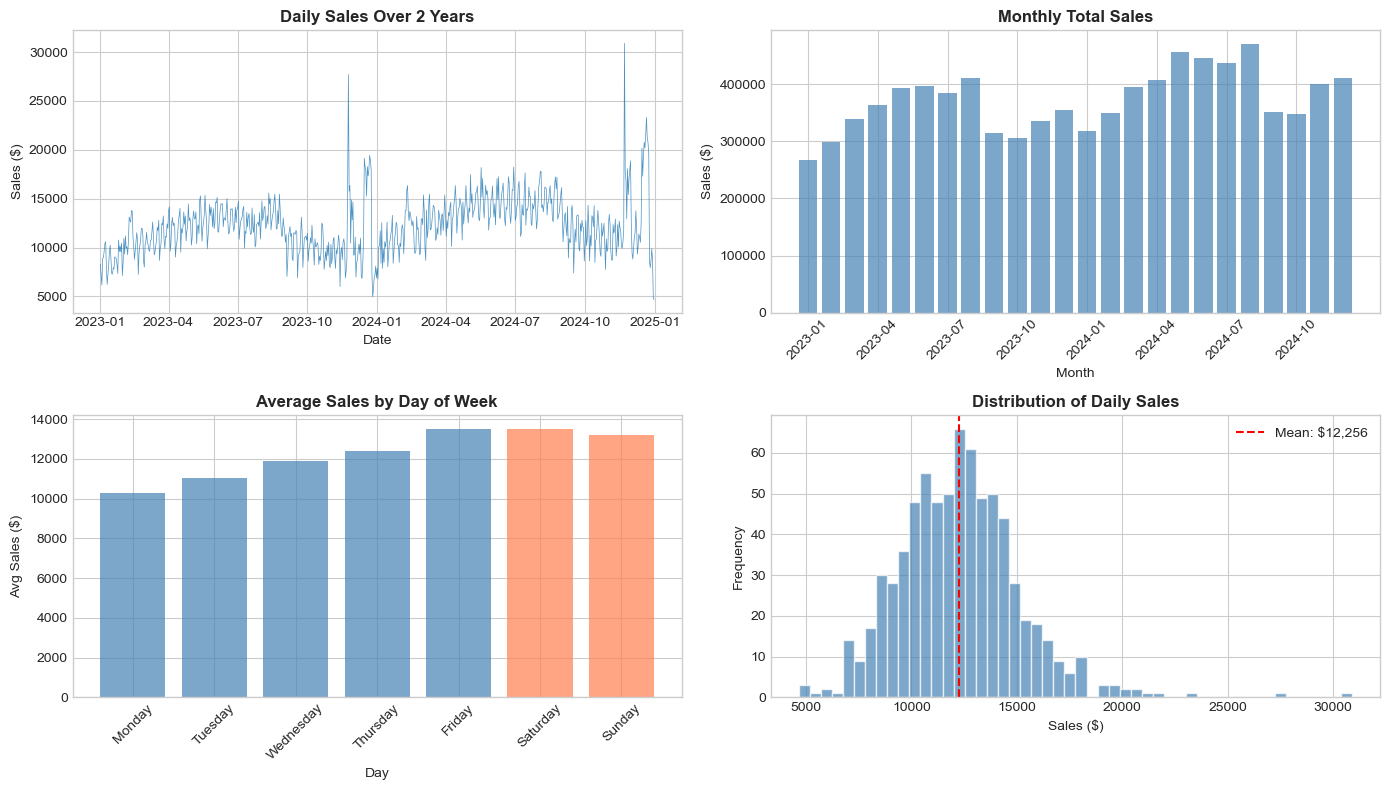

In [49]:
# =============================================================================
# VISUALIZE TIME SERIES DATA: 4-panel overview of our sales dataset
# Visualization is critical for understanding patterns before analysis
# =============================================================================

# Create a 2x2 grid of subplots
# figsize=(14, 8) sets the figure size in inches (width, height)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# -----------------------------------------------------------------------------
# SUBPLOT 1 (top-left): Full daily time series
# Shows overall trend, seasonality, and volatility at a glance
# -----------------------------------------------------------------------------
# .plot() creates a line chart; linewidth=0.5 for thin lines (less clutter)
# alpha=0.8 adds slight transparency
axes[0, 0].plot(df_sales['date'], df_sales['sales'], linewidth=0.5, alpha=0.8)
axes[0, 0].set_title('Daily Sales Over 2 Years', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Date')
axes[0, 0].set_ylabel('Sales ($)')

# -----------------------------------------------------------------------------
# SUBPLOT 2 (top-right): Monthly aggregated view
# Reduces noise to reveal underlying monthly patterns
# -----------------------------------------------------------------------------
# .dt.to_period('M') converts datetime to period (year-month)
# .groupby() groups rows by this period, then .sum() totals each month
monthly = df_sales.groupby(df_sales['date'].dt.to_period('M'))['sales'].sum()
# Bar chart with range() as x-axis positions
axes[0, 1].bar(range(len(monthly)), monthly.values, color='steelblue', alpha=0.7)
axes[0, 1].set_title('Monthly Total Sales', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Month')
axes[0, 1].set_ylabel('Sales ($)')
# Show every 3rd month label to avoid crowding
axes[0, 1].set_xticks(range(0, len(monthly), 3))
axes[0, 1].set_xticklabels([str(p) for p in monthly.index[::3]], rotation=45)

# -----------------------------------------------------------------------------
# SUBPLOT 3 (bottom-left): Day-of-week pattern
# Reveals weekly seasonality (weekday vs weekend differences)
# -----------------------------------------------------------------------------
# Group by day name and calculate mean sales for each day
dow_sales = df_sales.groupby('day_name')['sales'].mean()
# Define correct order (groupby alphabetizes by default)
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
# .reindex() reorders the Series to match our specified order
dow_sales = dow_sales.reindex(dow_order)
# Color weekends differently to highlight the pattern
colors = ['coral' if d in ['Saturday', 'Sunday'] else 'steelblue' for d in dow_order]
axes[1, 0].bar(dow_order, dow_sales.values, color=colors, alpha=0.7)
axes[1, 0].set_title('Average Sales by Day of Week', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Day')
axes[1, 0].set_ylabel('Avg Sales ($)')
axes[1, 0].tick_params(axis='x', rotation=45)

# -----------------------------------------------------------------------------
# SUBPLOT 4 (bottom-right): Distribution histogram
# Shows the shape of daily sales values (normal? skewed?)
# -----------------------------------------------------------------------------
# Histogram with 50 bins; edgecolor='white' separates bars visually
axes[1, 1].hist(df_sales['sales'], bins=50, color='steelblue', alpha=0.7, edgecolor='white')
# Add vertical line at the mean for reference
# linestyle='--' creates dashed line
axes[1, 1].axvline(df_sales['sales'].mean(), color='red', linestyle='--', label=f"Mean: ${df_sales['sales'].mean():,.0f}")
axes[1, 1].set_title('Distribution of Daily Sales', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Sales ($)')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].legend()

# Adjust spacing between subplots to prevent overlap
plt.tight_layout()
# Display the figure
plt.show()

### 💡 Instructor Discussion Points

Ask students:
1. "Can you spot the growth trend in the first chart?"
2. "Which months have the highest sales? Why might that be?"
3. "Why do you think weekends show higher sales in e-commerce?"

---

# 3. Time-Based Indexing and Selection

One of Pandas' most powerful features is the ability to use dates as indices for intuitive data selection.

## Setting a DateTime Index

In [50]:
# =============================================================================
# SETTING A DATETIME INDEX: Critical step for time series analysis
# A DatetimeIndex unlocks powerful time-based selection and resampling
# =============================================================================

# .set_index('column_name') moves a column to become the DataFrame index
# This is the FIRST STEP for most time series operations in pandas
# Note: This returns a NEW DataFrame (original df_sales is unchanged)
df_ts = df_sales.set_index('date')

# Verify the index is now a DatetimeIndex (not RangeIndex or other type)
# DatetimeIndex enables: partial string indexing, resampling, time slicing
print("Index type:", type(df_ts.index))

print("\nFirst 5 rows:")
# Notice: 'date' is no longer a column - it's now the index (leftmost)
df_ts.head()

Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>

First 5 rows:


,sales,year,month,day_of_week,day_name,is_weekend
date,,,,,,
2023-01-01,8317.67,2023,1,6,Sunday,True
2023-01-02,7148.10,2023,1,0,Monday,False
2023-01-03,6180.32,2023,1,1,Tuesday,False
2023-01-04,8890.58,2023,1,2,Wednesday,False
2023-01-05,8968.73,2023,1,3,Thursday,False


## Selecting Data by Date

With a DatetimeIndex, you can select data using intuitive string notation.

In [51]:
# =============================================================================
# PARTIAL STRING INDEXING: Select data using date strings
# DatetimeIndex allows intuitive date-based selection with .loc[]
# =============================================================================

# SELECT A SPECIFIC DATE using a date string
# Pandas automatically matches the string to the DatetimeIndex
# Returns a Series (single row) with all columns for that date
print("=== Select Specific Date ===")
print(df_ts.loc['2024-06-15'])

=== Select Specific Date ===
sales          16614.86
year               2024
month                 6
day_of_week           5
day_name       Saturday
is_weekend         True
Name: 2024-06-15 00:00:00, dtype: object


In [52]:
# =============================================================================
# SELECT AN ENTIRE MONTH: Use partial string 'YYYY-MM'
# Pandas automatically selects ALL dates matching that year-month
# =============================================================================

print("=== Select Entire Month (June 2024) ===")

# 'YYYY-MM' format selects all rows where the date is in that month
# This returns a DataFrame (multiple rows), not a Series
june_2024 = df_ts.loc['2024-06']

# Verify we got all 30 days of June
print(f"Records: {len(june_2024)}")

# Calculate total monthly sales with .sum()
print(f"Total sales: ${june_2024['sales'].sum():,.2f}")

# Preview the first few rows of the selected month
june_2024.head()

=== Select Entire Month (June 2024) ===
Records: 30
Total sales: $445,407.95


,sales,year,month,day_of_week,day_name,is_weekend
date,,,,,,
2024-06-01,16316.59,2024,6,5,Saturday,True
2024-06-02,14087.61,2024,6,6,Sunday,True
2024-06-03,13126.27,2024,6,0,Monday,False
2024-06-04,14473.16,2024,6,1,Tuesday,False
2024-06-05,12324.12,2024,6,2,Wednesday,False


In [53]:
# =============================================================================
# SELECT AN ENTIRE YEAR: Use just 'YYYY'
# Even simpler - just the year number as a string
# =============================================================================

print("=== Select Entire Year (2023) ===")

# 'YYYY' format selects all rows in that calendar year
# Returns 365 days (or 366 for leap years)
year_2023 = df_ts.loc['2023']

print(f"Records: {len(year_2023)}")
print(f"Total sales: ${year_2023['sales'].sum():,.2f}")

=== Select Entire Year (2023) ===
Records: 365
Total sales: $4,168,580.19


In [54]:
# =============================================================================
# DATE RANGE SLICING: Select data between two dates
# Use standard Python slice notation with date strings
# =============================================================================

print("=== Select Date Range (Q4 2024) ===")

# Slice syntax: df.loc['start_date':'end_date']
# IMPORTANT: Unlike regular Python slicing, BOTH endpoints are INCLUSIVE
# This is different from integer slicing where end is exclusive!
q4_2024 = df_ts.loc['2024-10-01':'2024-12-31']

print(f"Records: {len(q4_2024)}")
print(f"Total sales: ${q4_2024['sales'].sum():,.2f}")
print(f"\nFirst 5 days:")
q4_2024.head()

=== Select Date Range (Q4 2024) ===
Records: 92
Total sales: $1,160,066.68

First 5 days:


,sales,year,month,day_of_week,day_name,is_weekend
date,,,,,,
2024-10-01,10217.93,2024,10,1,Tuesday,False
2024-10-02,12750.03,2024,10,2,Wednesday,False
2024-10-03,10204.17,2024,10,3,Thursday,False
2024-10-04,10947.55,2024,10,4,Friday,False
2024-10-05,14328.44,2024,10,5,Saturday,True


In [55]:
# =============================================================================
# COMBINING DATE SELECTION WITH BOOLEAN FILTERING
# First select by date, then apply additional conditions
# =============================================================================

print("=== High Sales Days in December 2024 ===")

# Step 1: Select all of December 2024 using partial string indexing
dec_2024 = df_ts.loc['2024-12']

# Step 2: Apply boolean filter to find high-sales days
# Boolean indexing: df[condition] returns rows where condition is True
high_sales = dec_2024[dec_2024['sales'] > 15000]

print(f"Days with sales > $15,000: {len(high_sales)}")

# Select specific columns to display with double brackets [[col1, col2]]
high_sales[['sales', 'day_name']].head(10)

=== High Sales Days in December 2024 ===
Days with sales > $15,000: 10


,sales,day_name
date,,
2024-12-15,20185.13,Sunday
2024-12-16,17310.52,Monday
2024-12-17,19424.92,Tuesday
2024-12-18,20791.00,Wednesday
2024-12-19,20190.60,Thursday
2024-12-20,21570.70,Friday
2024-12-21,23327.60,Saturday
2024-12-22,21285.77,Sunday
2024-12-23,20769.74,Monday


## Using the `dt` Accessor

When your datetime is a column (not index), use the `.dt` accessor to extract components.

In [56]:
# =============================================================================
# THE .dt ACCESSOR: Extract datetime properties from a Series
# Use when datetime is a COLUMN (not the index)
# Similar to .str accessor for string operations
# =============================================================================

# df_sales has 'date' as a column (not index), so we use .dt accessor
print("Using .dt accessor on a datetime column:")

# .dt.year - Extract year from each datetime value in the Series
# .unique() returns array of distinct values
print(f"\nYears: {df_sales['date'].dt.year.unique()}")

# .dt.month - Extract month number (1-12) from each value
# sorted() orders the unique months chronologically
print(f"\nMonths present: {sorted(df_sales['date'].dt.month.unique())}")

# =============================================================================
# COMBINING .dt ACCESSOR WITH BOOLEAN FILTERING
# Common pattern: filter rows by datetime component
# =============================================================================

# Filter for summer months (June=6, July=7, August=8)
# .isin([list]) returns True for values in the list
# This is more readable than: (month == 6) | (month == 7) | (month == 8)
summer = df_sales[df_sales['date'].dt.month.isin([6, 7, 8])]

print(f"\nSummer records: {len(summer)}")
print(f"Summer total sales: ${summer['sales'].sum():,.2f}")

Using .dt accessor on a datetime column:

Years: [2023 2024]

Months present: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]

Summer records: 184
Summer total sales: $2,545,683.88


In [57]:
# =============================================================================
# GROUPBY WITH .dt ACCESSOR: Aggregate data by datetime components
# Common pattern for monthly/weekly/yearly summaries
# =============================================================================

print("First and Last Day of Each Month in 2024:")

# Filter to 2024 data only using .dt.year
# .copy() creates independent copy to avoid SettingWithCopyWarning
df_2024 = df_sales[df_sales['date'].dt.year == 2024].copy()

# Group by month number and get FIRST row of each group
# .dt.month extracts month (1-12) for grouping
# .first() returns first row in each group (assumes data is sorted by date)
first_days = df_2024.groupby(df_2024['date'].dt.month).first()

# .last() returns last row in each group (last day of each month)
last_days = df_2024.groupby(df_2024['date'].dt.month).last()

# Create a summary DataFrame comparing first and last day sales
# .values extracts the underlying numpy array from the Series
summary = pd.DataFrame({
    'First Day Sales': first_days['sales'].values,
    'Last Day Sales': last_days['sales'].values
}, index=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])

summary

First and Last Day of Each Month in 2024:


,First Day Sales,Last Day Sales
Jan,7892.77,10451.71
Feb,10088.95,12948.28
Mar,12336.69,13130.86
Apr,11154.16,12517.70
May,14062.93,15089.13
Jun,16316.59,15826.84
Jul,12776.71,14394.80
Aug,16247.97,16136.08
Sep,13689.89,8630.69
Oct,10217.93,9822.12


---

# 4. Resampling and Frequency Conversion

**Resampling** is one of the most important operations in time series analysis. It allows you to:
- **Downsample**: Aggregate data to a lower frequency (daily → weekly)
- **Upsample**: Convert to a higher frequency (monthly → daily, with interpolation)

## Downsampling (Aggregation)

Most common use case: You have granular data and want summary statistics.

In [58]:
# =============================================================================
# RESAMPLING: Change the frequency of time series data
# CRITICAL: DataFrame/Series MUST have a DatetimeIndex for .resample() to work
# =============================================================================

# Ensure we have DatetimeIndex (if not already set)
df_ts = df_sales.set_index('date')

# =============================================================================
# DOWNSAMPLING: Aggregate from higher to lower frequency (daily → weekly)
# =============================================================================

# .resample('W') groups data by week (W = weekly, anchored on Sunday)
# This creates a Resampler object (similar to GroupBy)
# .sum() aggregates all values within each week
# Result: One value per week = sum of all daily sales in that week
weekly_sales = df_ts['sales'].resample('W').sum()

print("Weekly Sales (Total):")
# Notice: Index shows the END date of each week (Sunday by default)
weekly_sales.head(10)

Weekly Sales (Total):


date
2023-01-01     8317.67
2023-01-08    61836.58
2023-01-15    58229.89
2023-01-22    57251.17
2023-01-29    66109.67
2023-02-05    67087.30
2023-02-12    85923.54
2023-02-19    72808.25
2023-02-26    72696.30
2023-03-05    69888.48
Freq: W-SUN, Name: sales, dtype: float64

In [86]:
# =============================================================================
# MULTIPLE AGGREGATIONS: Calculate several statistics per period
# Use .agg() with a list of (name, function) tuples or just function names
# =============================================================================

# .resample('ME') - 'ME' = Month End (last day of each month)
# Note: Older pandas versions used 'M', newer versions use 'ME'
# .agg() accepts multiple aggregation functions at once
# Format: list of tuples (output_column_name, aggregation_function)
# monthly_stats = df_ts['sales'].resample('ME').agg([
#     ('total', 'sum'),    # Total monthly sales
#     ('average', 'mean'), # Average daily sales in that month
#     ('min', 'min'),      # Lowest daily sales
#     ('max', 'max'),      # Highest daily sales
#     ('std', 'std')       # Standard deviation (volatility measure)
# ])
monthly_stats = (
    df_ts[['sales']]              # ensure it's a DataFrame
    .resample('ME')
    .agg([
        ('total', 'sum'),
        ('average', 'mean'),
        ('min', 'min'),
        ('max', 'max'),
        ('std', 'std')
    ])
)


print("Monthly Sales Statistics:")
# .round(2) rounds all numeric values to 2 decimal places
# .head(12) shows first 12 rows (one year of monthly data)
monthly_stats.round(2).head(12)

Monthly Sales Statistics:


sales                                       
                total   average       min       max      std
date                                                        
2023-01-31  267312.16   8622.97   6180.32  10771.03  1290.27
2023-02-28  299520.84  10697.17   7260.80  13811.22  1641.61
2023-03-31  340140.67  10972.28   8682.33  13242.71  1142.38
2023-04-30  363499.50  12116.65   9031.25  14454.57  1432.94
2023-05-31  393991.45  12709.40   9891.11  15354.13  1442.21
2023-06-30  396932.30  13231.08  11406.41  15140.17  1146.66
2023-07-31  384061.13  12389.07   9924.99  14764.50  1274.34
2023-08-31  411639.04  13278.68  11164.93  15583.80  1274.05
2023-09-30  314222.53  10474.08   6893.65  13116.63  1531.40
2023-10-31  306540.37   9888.40   7767.72  12509.35  1299.98
2023-11-30  335561.10  11185.37   6005.92  27705.30  4089.61
2023-12-31  355159.10  11456.75   4983.51  19439.93  4882.95

In [60]:
# =============================================================================
# QUARTERLY RESAMPLING: Business reporting often uses quarters
# 'QE' = Quarter End (last day of Mar, Jun, Sep, Dec)
# =============================================================================

# .resample('QE') groups data by calendar quarter
# Q1: Jan-Mar (ends Mar 31), Q2: Apr-Jun (ends Jun 30)
# Q3: Jul-Sep (ends Sep 30), Q4: Oct-Dec (ends Dec 31)
# .agg(['sum', 'mean']) applies both functions, creating multi-column result
quarterly_sales = df_ts['sales'].resample('QE').agg(['sum', 'mean'])

# Rename columns for better readability
# .columns attribute can be assigned a list of new names
quarterly_sales.columns = ['Total Sales', 'Daily Average']

print("Quarterly Performance:")
# Display all quarters (8 quarters for 2 years of data)
quarterly_sales.round(2)

Quarterly Performance:


,Total Sales,Daily Average
date,,
2023-03-31,906973.67,10077.49
2023-06-30,1154423.25,12685.97
2023-09-30,1109922.70,12064.38
2023-12-31,997260.57,10839.79
2024-03-31,1062821.71,11679.36
2024-06-30,1308536.13,14379.52
2024-09-30,1258994.79,13684.73
2024-12-31,1160066.68,12609.42


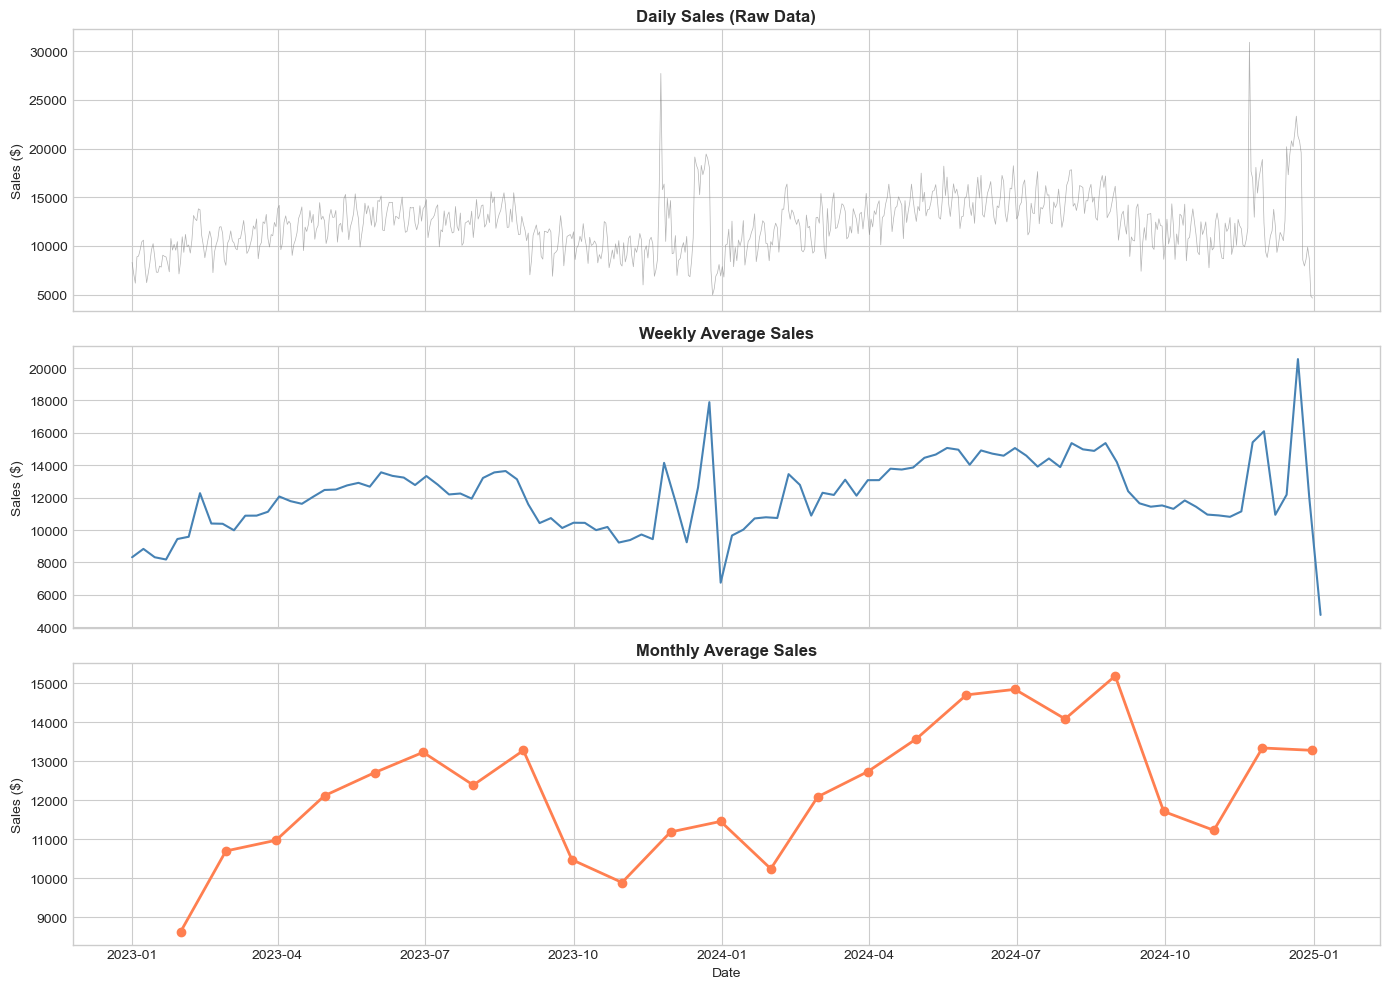


💡 Notice how aggregation smooths out the daily noise, revealing the underlying trends!


In [61]:
# =============================================================================
# VISUALIZING RESAMPLING: Compare different aggregation frequencies
# Key insight: Lower frequencies smooth out noise, revealing trends
# =============================================================================

# Create 3 vertically stacked subplots
# sharex=True links x-axes so zooming/panning affects all plots equally
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# -----------------------------------------------------------------------------
# PANEL 1: Daily data (raw, noisy)
# -----------------------------------------------------------------------------
# df_ts.index is the DatetimeIndex (dates)
# Thin line (0.5) with transparency (alpha=0.6) to show density of points
axes[0].plot(df_ts.index, df_ts['sales'], linewidth=0.5, alpha=0.6, color='gray')
axes[0].set_title('Daily Sales (Raw Data)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Sales ($)')

# -----------------------------------------------------------------------------
# PANEL 2: Weekly average (moderate smoothing)
# -----------------------------------------------------------------------------
# .resample('W').mean() - average of all daily values in each week
# Reduces 7 daily points to 1 weekly point
weekly_avg = df_ts['sales'].resample('W').mean()
axes[1].plot(weekly_avg.index, weekly_avg.values, linewidth=1.5, color='steelblue')
axes[1].set_title('Weekly Average Sales', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Sales ($)')

# -----------------------------------------------------------------------------
# PANEL 3: Monthly average (heavy smoothing)
# -----------------------------------------------------------------------------
# .resample('ME').mean() - average of all daily values in each month
# Reduces ~30 daily points to 1 monthly point
# marker='o' adds dots at each data point (helpful with fewer points)
monthly_avg = df_ts['sales'].resample('ME').mean()
axes[2].plot(monthly_avg.index, monthly_avg.values, linewidth=2, color='coral', marker='o')
axes[2].set_title('Monthly Average Sales', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Date')
axes[2].set_ylabel('Sales ($)')

plt.tight_layout()
plt.show()

# KEY TEACHING POINT: Resampling is a trade-off between detail and clarity
print("\n💡 Notice how aggregation smooths out the daily noise, revealing the underlying trends!")

## Upsampling (Increasing Frequency)

Less common, but useful when you need to align datasets with different frequencies.

In [62]:
# =============================================================================
# UPSAMPLING: Convert from lower to higher frequency (monthly → daily)
# This CREATES gaps (NaN values) that need to be filled
# =============================================================================

# First, create monthly aggregated data (starting point for upsampling)
# .resample('ME').sum() gives us one value per month
monthly_data = df_ts['sales'].resample('ME').sum()
print("Monthly data:")
print(monthly_data.head())

# =============================================================================
# UPSAMPLE TO DAILY: .resample('D').asfreq()
# .asfreq() creates the new frequency but puts NaN where no data exists
# =============================================================================

# .resample('D') - request daily frequency
# .asfreq() - "as frequency" - just convert without filling
# Result: Only month-end dates have values, all other dates are NaN
daily_upsampled = monthly_data.resample('D').asfreq()

print("\nUpsampled to daily (with NaN):")
# Notice: Only dates that were in the original monthly data have values
# All other dates (days between month ends) are NaN
print(daily_upsampled.head(35))

Monthly data:
date
2023-01-31    267312.16
2023-02-28    299520.84
2023-03-31    340140.67
2023-04-30    363499.50
2023-05-31    393991.45
Freq: ME, Name: sales, dtype: float64

Upsampled to daily (with NaN):
date
2023-01-31    267312.16
2023-02-01          NaN
2023-02-02          NaN
2023-02-03          NaN
2023-02-04          NaN
2023-02-05          NaN
2023-02-06          NaN
2023-02-07          NaN
2023-02-08          NaN
2023-02-09          NaN
2023-02-10          NaN
2023-02-11          NaN
2023-02-12          NaN
2023-02-13          NaN
2023-02-14          NaN
2023-02-15          NaN
2023-02-16          NaN
2023-02-17          NaN
2023-02-18          NaN
2023-02-19          NaN
2023-02-20          NaN
2023-02-21          NaN
2023-02-22          NaN
2023-02-23          NaN
2023-02-24          NaN
2023-02-25          NaN
2023-02-26          NaN
2023-02-27          NaN
2023-02-28    299520.84
2023-03-01          NaN
2023-03-02          NaN
2023-03-03          NaN
2023-03-04        

In [63]:
# =============================================================================
# FILLING UPSAMPLED DATA: Handle the NaN values created by upsampling
# Two main approaches: forward fill and interpolation
# =============================================================================

# METHOD 1: FORWARD FILL (ffill)
# Copies the last known value forward until the next known value
# Use case: When values should stay constant (e.g., monthly budget applies to all days)
# .ffill() is shorthand for .fillna(method='ffill')
daily_ffill = monthly_data.resample('D').ffill()
print("Forward fill:")
# Notice: All days in a month have the same value (the month-end total)
print(daily_ffill.head(10))

# METHOD 2: LINEAR INTERPOLATION
# Calculates intermediate values between known points using linear interpolation
# Use case: When you expect gradual change between values (e.g., temperature)
# .interpolate(method='linear') draws a straight line between known values
daily_interp = monthly_data.resample('D').interpolate(method='linear')
print("\nLinear interpolation:")
# Notice: Values gradually increase/decrease between month-end values
print(daily_interp.head(10))

Forward fill:
date
2023-01-31    267312.16
2023-02-01    267312.16
2023-02-02    267312.16
2023-02-03    267312.16
2023-02-04    267312.16
2023-02-05    267312.16
2023-02-06    267312.16
2023-02-07    267312.16
2023-02-08    267312.16
2023-02-09    267312.16
Freq: D, Name: sales, dtype: float64

Linear interpolation:
date
2023-01-31    267312.16
2023-02-01    268462.47
2023-02-02    269612.78
2023-02-03    270763.09
2023-02-04    271913.40
2023-02-05    273063.71
2023-02-06    274214.02
2023-02-07    275364.33
2023-02-08    276514.64
2023-02-09    277664.95
Freq: D, Name: sales, dtype: float64


### 💡 Instructor Note

**Key Teaching Point**: Ask students when they might need to upsample data.

Examples:
- Combining monthly economic data with daily stock prices
- Creating a continuous timeline for visualization
- Preparing data for time series models that require regular intervals

---

# 5. Rolling Windows and Moving Statistics

Rolling (or moving) statistics compute values over a sliding window of time. This is essential for:
- **Smoothing noisy data** (moving averages)
- **Identifying trends** (moving average crossovers)
- **Computing running statistics** (rolling volatility, cumulative sums)

## Moving Average

In [64]:
# =============================================================================
# ROLLING WINDOWS: Compute statistics over a sliding window of data
# Also called "moving" statistics (moving average, moving std, etc.)
# =============================================================================

# Create a working copy of the sales data
# Double brackets [[col]] return DataFrame instead of Series
df_rolling = df_ts[['sales']].copy()

# =============================================================================
# MOVING AVERAGE (MA): Smooth data by averaging over a window
# .rolling(window=N) creates a Rolling object, then apply aggregation
# =============================================================================

# 7-DAY MOVING AVERAGE (1 week)
# For each day, calculate the average of that day + previous 6 days
# window=7 means the window includes 7 observations
# First 6 values will be NaN (not enough data to fill the window)
df_rolling['MA_7'] = df_rolling['sales'].rolling(window=7).mean()

# 30-DAY MOVING AVERAGE (~1 month)
# Larger window = more smoothing, but more lag in detecting changes
df_rolling['MA_30'] = df_rolling['sales'].rolling(window=30).mean()

# 90-DAY MOVING AVERAGE (~1 quarter)
# Very smooth - reveals long-term trends, hides short-term fluctuations
df_rolling['MA_90'] = df_rolling['sales'].rolling(window=90).mean()

print("Rolling Averages:")
# Notice: First 6 rows have NaN for MA_7, first 29 for MA_30, first 89 for MA_90
# This is because there aren't enough prior observations to fill the window
df_rolling.head(35)

Rolling Averages:


,sales,MA_7,MA_30,MA_90
date,,,,
2023-01-01,8317.67,NaN,NaN,NaN
2023-01-02,7148.10,NaN,NaN,NaN
2023-01-03,6180.32,NaN,NaN,NaN
2023-01-04,8890.58,NaN,NaN,NaN
2023-01-05,8968.73,NaN,NaN,NaN
2023-01-06,9620.50,NaN,NaN,NaN
2023-01-07,10428.19,8507.727143,NaN,NaN
2023-01-08,10600.16,8833.797143,NaN,NaN
2023-01-09,7796.51,8926.427143,NaN,NaN


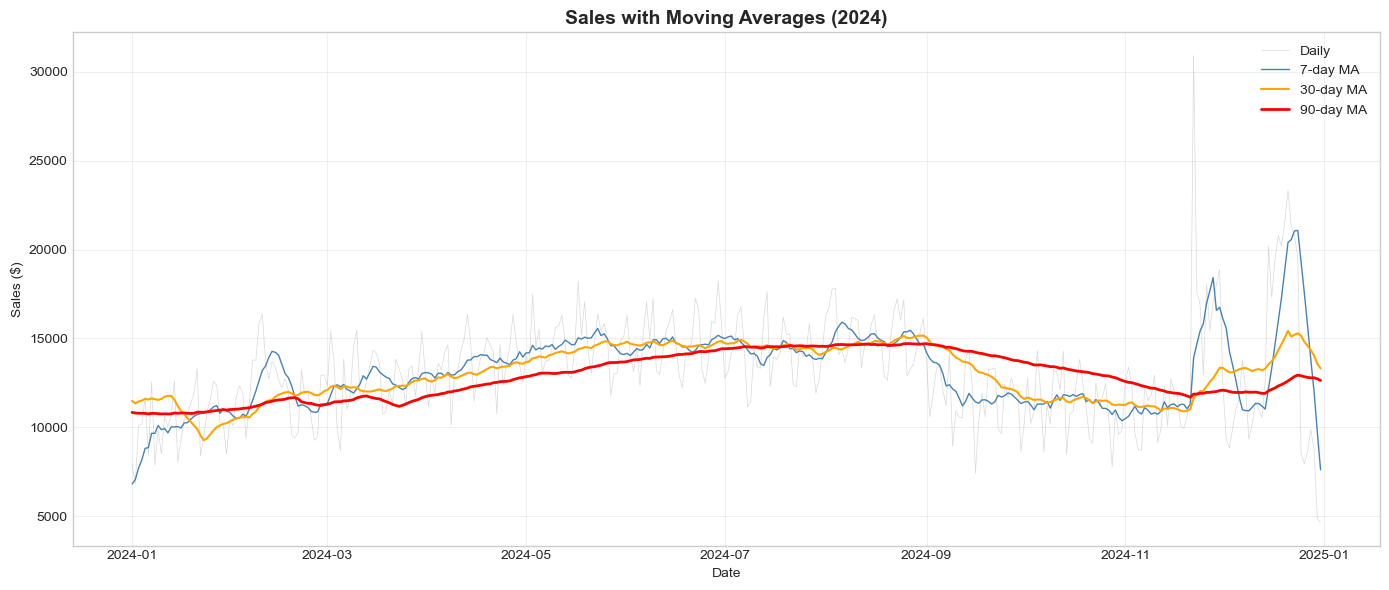

💡 Longer windows = smoother lines, but slower to react to changes


In [65]:
# =============================================================================
# VISUALIZING MOVING AVERAGES: Compare different window sizes
# =============================================================================

# Create a single subplot
fig, ax = plt.subplots(figsize=(14, 6))

# Filter to 2024 data only for clearer visualization
# Using partial string indexing on the DatetimeIndex
df_2024 = df_rolling.loc['2024']

# Plot raw daily data as faint background line
# alpha=0.3 makes it semi-transparent so MAs stand out
ax.plot(df_2024.index, df_2024['sales'], linewidth=0.5, alpha=0.3, color='gray', label='Daily')

# Plot 7-day MA - responds quickly to changes, still somewhat noisy
ax.plot(df_2024.index, df_2024['MA_7'], linewidth=1, color='steelblue', label='7-day MA')

# Plot 30-day MA - medium smoothing, good for monthly trends
ax.plot(df_2024.index, df_2024['MA_30'], linewidth=1.5, color='orange', label='30-day MA')

# Plot 90-day MA - very smooth, shows long-term direction
ax.plot(df_2024.index, df_2024['MA_90'], linewidth=2, color='red', label='90-day MA')

ax.set_title('Sales with Moving Averages (2024)', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Sales ($)')
# legend() displays the labels we assigned to each plot
ax.legend()
# grid(alpha=0.3) adds subtle gridlines
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# KEY INSIGHT: Window size is a bias-variance tradeoff
print("💡 Longer windows = smoother lines, but slower to react to changes")

## Other Rolling Statistics

In [66]:
# =============================================================================
# OTHER ROLLING STATISTICS: Not just mean - any aggregation works!
# =============================================================================

# ROLLING STANDARD DEVIATION (Volatility Measure)
# Measures how spread out the values are in the window
# High std = high volatility, low std = stable period
# Finance uses this extensively for risk measurement
df_rolling['rolling_std_30'] = df_rolling['sales'].rolling(window=30).std()

# ROLLING MIN AND MAX (Range Indicators)
# Useful for identifying support/resistance levels in finance
# Or tracking operational bounds in manufacturing
df_rolling['rolling_min_30'] = df_rolling['sales'].rolling(window=30).min()
df_rolling['rolling_max_30'] = df_rolling['sales'].rolling(window=30).max()

# ROLLING SUM (Cumulative over window)
# E.g., "total sales in the last 7 days" - common business metric
# Different from cumsum() which accumulates from the start
df_rolling['rolling_sum_7'] = df_rolling['sales'].rolling(window=7).sum()

print("Various rolling statistics:")
# Display selected columns for June 2024 to see the statistics in action
df_rolling[['sales', 'MA_30', 'rolling_std_30', 'rolling_min_30', 'rolling_max_30']].loc['2024-06'].head(10)

Various rolling statistics:


,sales,MA_30,rolling_std_30,rolling_min_30,rolling_max_30
date,,,,,
2024-06-01,16316.59,14816.374333,1513.399402,11782.73,18193.57
2024-06-02,14087.61,14703.320000,1432.116353,11782.73,18193.57
2024-06-03,13126.27,14656.517333,1460.623551,11782.73,18193.57
2024-06-04,14473.16,14621.744667,1451.839075,11782.73,18193.57
2024-06-05,12324.12,14596.665667,1485.558791,11782.73,18193.57
2024-06-06,15248.29,14647.253000,1480.884593,11782.73,18193.57
2024-06-07,17060.57,14756.710667,1534.708856,11782.73,18193.57
2024-06-08,14922.51,14772.292667,1533.913332,11782.73,18193.57
2024-06-09,17251.65,14827.014667,1592.974384,11782.73,18193.57


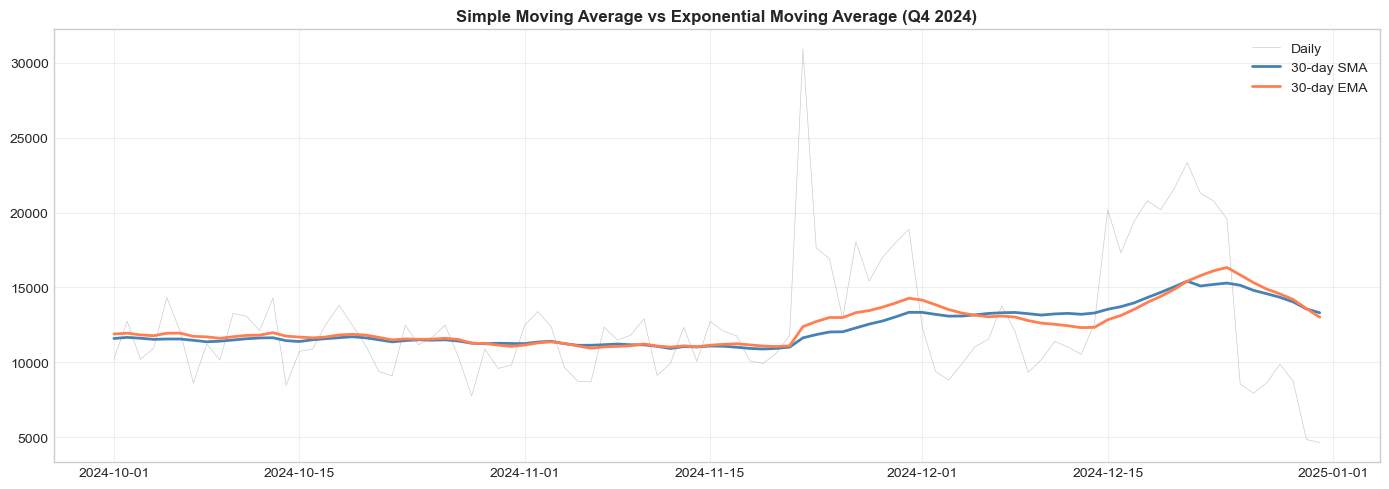

💡 EMA reacts faster to recent changes than SMA


In [67]:
# =============================================================================
# EXPONENTIAL MOVING AVERAGE (EMA): Weighted average favoring recent data
# Unlike SMA where all points have equal weight, EMA gives more weight to recent values
# =============================================================================

# .ewm() = Exponential Weighted Moving (functions)
# span=30 means the "center of mass" is roughly equivalent to a 30-period SMA
# but with exponentially decaying weights
# Alternative: use halflife=N to specify when weight drops to 50%
df_rolling['EMA_30'] = df_rolling['sales'].ewm(span=30).mean()

# =============================================================================
# COMPARE SMA vs EMA: See how EMA reacts faster to changes
# =============================================================================

fig, ax = plt.subplots(figsize=(14, 5))

# Select Q4 2024 to focus on the Christmas spike pattern
df_q4 = df_rolling.loc['2024-10':'2024-12']

# Plot daily data as faint background
ax.plot(df_q4.index, df_q4['sales'], linewidth=0.5, alpha=0.4, color='gray', label='Daily')

# Simple Moving Average (SMA) - all 30 days weighted equally
ax.plot(df_q4.index, df_q4['MA_30'], linewidth=2, color='steelblue', label='30-day SMA')

# Exponential Moving Average (EMA) - recent days weighted more heavily
# Notice: EMA will respond faster to the Christmas sales spike
ax.plot(df_q4.index, df_q4['EMA_30'], linewidth=2, color='coral', label='30-day EMA')

ax.set_title('Simple Moving Average vs Exponential Moving Average (Q4 2024)', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# KEY INSIGHT: EMA is preferred when recent data matters more
print("💡 EMA reacts faster to recent changes than SMA")

## Centered vs Left-Aligned Windows

By default, rolling windows are "right-aligned" (use past data). For analysis, you might want centered windows.

In [68]:
# =============================================================================
# WINDOW ALIGNMENT: Right-aligned (default) vs Centered windows
# This matters for forecasting vs. retrospective analysis
# =============================================================================

# RIGHT-ALIGNED (default): Window includes current + past N-1 observations
# For Jan 7: averages Jan 1,2,3,4,5,6,7 - only uses data available at that time
# Use for: FORECASTING - because you can't use future data to predict
ma_right = df_ts['sales'].rolling(window=7).mean()

# CENTERED: Window is centered on current observation
# For Jan 7: averages Jan 4,5,6,7,8,9,10 - uses 3 past + current + 3 future
# center=True shifts the window so current point is in the middle
# Use for: ANALYSIS - when you have all data and want smooth trend
ma_centered = df_ts['sales'].rolling(window=7, center=True).mean()

# =============================================================================
# COMPARE THE TWO ALIGNMENTS
# =============================================================================

# Select a sample period to compare
sample = df_ts.loc['2024-01-01':'2024-01-15', ['sales']].copy()
sample['MA_right'] = ma_right
sample['MA_centered'] = ma_centered

print("Right-aligned vs Centered Moving Average:")
# Notice: Right-aligned has NaN for first 6 rows (need 7 points)
# Centered has NaN at BOTH start AND end (needs 3 points on each side)
sample.round(2)

Right-aligned vs Centered Moving Average:


,sales,MA_right,MA_centered
date,,,
2024-01-01,7892.77,6805.11,8173.47
2024-01-02,6810.84,7066.15,8815.56
2024-01-03,10094.06,7706.96,8856.37
2024-01-04,10171.05,8173.47,9661.08
2024-01-05,11719.57,8815.56,9658.25
2024-01-06,8388.36,8856.37,10093.85
2024-01-07,12550.93,9661.08,9863.75
2024-01-08,7872.97,9658.25,9927.36
2024-01-09,9860.03,10093.85,9686.22


---

# 6. Handling Missing Data in Time Series

Time series data often has gaps:
- Missing dates (no data recorded)
- Missing values (data recorded but value is NaN)
- Irregular intervals

## Creating Data with Gaps

In [69]:
# =============================================================================
# HANDLING MISSING DATA IN TIME SERIES
# Real-world data often has gaps due to sensor failures, holidays, etc.
# =============================================================================

# Set seed for reproducible random data
np.random.seed(42)

# Create a date range for our simulated sensor data
dates_with_gaps = pd.date_range('2024-01-01', periods=30, freq='D')

# Generate random values around 50 (simulating sensor readings)
# np.random.randn() generates standard normal distribution (mean=0, std=1)
# Multiply by 10 and add 50 to shift to mean=50, std=10
values = np.random.randn(30) * 10 + 50  # Random values around 50

# =============================================================================
# INTRODUCE MISSING VALUES: Simulating sensor dropouts/failures
# =============================================================================

# Indices where we'll set values to NaN (missing)
# This simulates real-world scenarios: sensor offline, transmission errors, etc.
missing_indices = [5, 6, 12, 13, 14, 22]

# Set these indices to NaN (Not a Number) - pandas' representation of missing data
values[missing_indices] = np.nan

# Create DataFrame with DatetimeIndex
df_gaps = pd.DataFrame({'value': values}, index=dates_with_gaps)

print("Data with missing values:")
print(df_gaps.head(20))

# .isna() returns True for NaN values, .sum() counts them
print(f"\nMissing values: {df_gaps['value'].isna().sum()}")

Data with missing values:
                value
2024-01-01  54.967142
2024-01-02  48.617357
2024-01-03  56.476885
2024-01-04  65.230299
2024-01-05  47.658466
2024-01-06        NaN
2024-01-07        NaN
2024-01-08  57.674347
2024-01-09  45.305256
2024-01-10  55.425600
2024-01-11  45.365823
2024-01-12  45.342702
2024-01-13        NaN
2024-01-14        NaN
2024-01-15        NaN
2024-01-16  44.377125
2024-01-17  39.871689
2024-01-18  53.142473
2024-01-19  40.919759
2024-01-20  35.876963

Missing values: 6


## Filling Missing Values

In [70]:
# =============================================================================
# FILLING MISSING VALUES: Multiple strategies for different use cases
# =============================================================================

# Create a copy to compare different filling methods side by side
df_filled = df_gaps.copy()

# METHOD 1: FORWARD FILL (ffill)
# Propagate the LAST valid observation forward to fill NaN
# Use case: Data that should persist until changed (e.g., settings, prices)
# Shorthand for .fillna(method='ffill')
df_filled['ffill'] = df_gaps['value'].ffill()

# METHOD 2: BACKWARD FILL (bfill)
# Use the NEXT valid observation to fill NaN backward
# Use case: When future value is more relevant (rare in time series)
# Shorthand for .fillna(method='bfill')
df_filled['bfill'] = df_gaps['value'].bfill()

# METHOD 3: LINEAR INTERPOLATION
# Draw straight line between known points, estimate values in between
# Use case: Continuous data where gradual change is expected (temperature)
# method='linear' is the default for .interpolate()
df_filled['interpolate'] = df_gaps['value'].interpolate(method='linear')

# METHOD 4: TIME-BASED INTERPOLATION
# Like linear, but considers ACTUAL time gaps (not just row positions)
# Important when data has irregular intervals
# method='time' requires a DatetimeIndex
df_filled['interpolate_time'] = df_gaps['value'].interpolate(method='time')

# METHOD 5: FILL WITH MEAN
# Replace all NaN with the column's mean value
# .fillna(value) replaces NaN with the specified value
# Use case: When you need to preserve overall average (ML feature engineering)
df_filled['mean_fill'] = df_gaps['value'].fillna(df_gaps['value'].mean())

print("Comparison of filling methods:")
# Compare all methods side by side
df_filled.round(2).head(20)

Comparison of filling methods:


,value,ffill,bfill,interpolate,interpolate_time,mean_fill
2024-01-01,54.97,54.97,54.97,54.97,54.97,54.97
2024-01-02,48.62,48.62,48.62,48.62,48.62,48.62
2024-01-03,56.48,56.48,56.48,56.48,56.48,56.48
2024-01-04,65.23,65.23,65.23,65.23,65.23,65.23
2024-01-05,47.66,47.66,47.66,47.66,47.66,47.66
2024-01-06,NaN,47.66,57.67,51.00,51.00,48.47
2024-01-07,NaN,47.66,57.67,54.34,54.34,48.47
2024-01-08,57.67,57.67,57.67,57.67,57.67,57.67
2024-01-09,45.31,45.31,45.31,45.31,45.31,45.31
2024-01-10,55.43,55.43,55.43,55.43,55.43,55.43


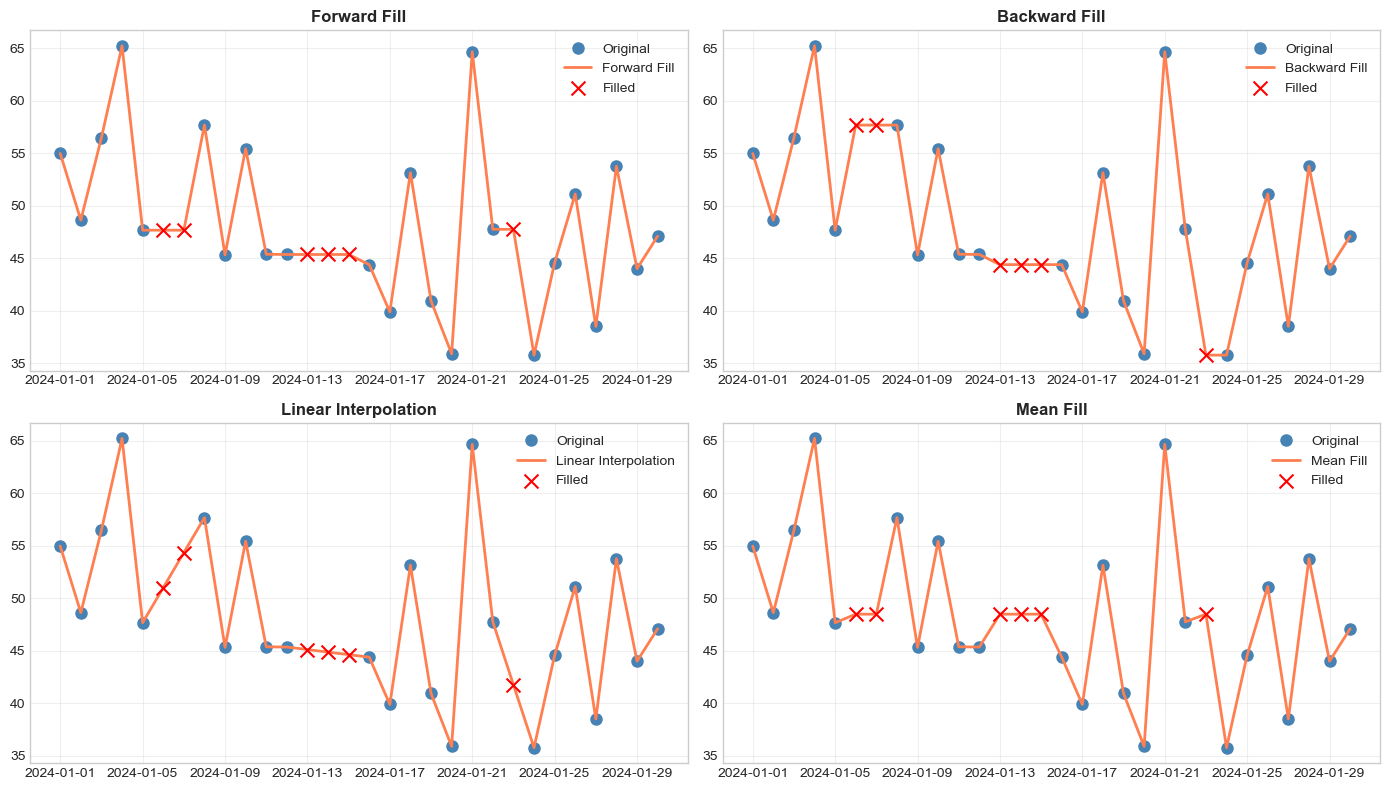

In [72]:
# =============================================================================
# VISUALIZE FILLING METHODS: See how each strategy handles gaps differently
# =============================================================================

# Create 2x2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Define which methods to plot and their display titles
methods = ['ffill', 'bfill', 'interpolate', 'mean_fill']
titles = ['Forward Fill', 'Backward Fill', 'Linear Interpolation', 'Mean Fill']

# Loop through axes and methods together using zip()
# axes.flat flattens the 2D array of axes into 1D for easy iteration
for ax, method, title in zip(axes.flat, methods, titles):
    # Plot original data points as blue dots
    # 'o' marker style creates circles; markersize=8 sets their size
    ax.plot(df_filled.index, df_filled['value'], 'o', color='steelblue', markersize=8, label='Original')
    
    # Plot the filled series as a coral-colored line
    ax.plot(df_filled.index, df_filled[method], '-', color='coral', linewidth=2, label=title)
    
    # =============================================================================
    # HIGHLIGHT WHERE FILLING OCCURRED: Mark the imputed values
    # =============================================================================
    # Create boolean mask: True where original data was NaN
    mask = df_gaps['value'].isna()
    # Plot only the filled points with red X markers
    # zorder=5 ensures these markers appear on top of other elements
    ax.scatter(df_filled.index[mask], df_filled[method][mask], 
               color='red', s=100, zorder=5, marker='x', label='Filled')
    
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 💡 Instructor Discussion: When to Use Each Method?

| Method | Best For | Example |
|--------|----------|--------|
| **Forward Fill** | Sensor data where last reading is still valid | Temperature sensor |
| **Backward Fill** | When future value is known/expected | Pre-announced prices |
| **Interpolation** | Smoothly varying data | GPS coordinates |
| **Mean Fill** | When no trend, random missing | Survey responses |
| **Don't fill!** | When missing data is meaningful | System outages |

**Ask students**: "For stock prices, which method would be most appropriate?"

---

# 7. Time Zones

Working with data from different time zones is common in global applications.

## Localizing and Converting Time Zones

In [73]:
# Create a naive (no timezone) timestamp
ts_naive = pd.Timestamp('2024-06-15 14:30:00')
print(f"Naive timestamp: {ts_naive}")
print(f"Has timezone: {ts_naive.tz}")

Naive timestamp: 2024-06-15 14:30:00
Has timezone: None


In [74]:
# Localize: assign a timezone (this IS the time in that zone)
ts_nyc = ts_naive.tz_localize('America/New_York')
print(f"Localized to NYC: {ts_nyc}")

# Convert: show the same moment in a different timezone
ts_london = ts_nyc.tz_convert('Europe/London')
ts_tokyo = ts_nyc.tz_convert('Asia/Tokyo')
ts_sydney = ts_nyc.tz_convert('Australia/Sydney')

print(f"\nSame moment in different time zones:")
print(f"New York:  {ts_nyc}")
print(f"London:    {ts_london}")
print(f"Tokyo:     {ts_tokyo}")
print(f"Sydney:    {ts_sydney}")

Localized to NYC: 2024-06-15 14:30:00-04:00

Same moment in different time zones:
New York:  2024-06-15 14:30:00-04:00
London:    2024-06-15 19:30:00+01:00
Tokyo:     2024-06-16 03:30:00+09:00
Sydney:    2024-06-16 04:30:00+10:00


In [75]:
# Working with timezone-aware Series/DataFrames
dates = pd.date_range('2024-06-15', periods=5, freq='H', tz='America/New_York')
df_tz = pd.DataFrame({
    'NYC_time': dates,
    'value': [100, 105, 103, 108, 110]
})

# Convert to other timezones
df_tz['London_time'] = df_tz['NYC_time'].dt.tz_convert('Europe/London')
df_tz['Tokyo_time'] = df_tz['NYC_time'].dt.tz_convert('Asia/Tokyo')

print("Multi-timezone data:")
df_tz

Multi-timezone data:


,NYC_time,value,London_time,Tokyo_time
0,2024-06-15 00:00:00-04:00,100,2024-06-15 05:00:00+01:00,2024-06-15 13:00:00+09:00
1,2024-06-15 01:00:00-04:00,105,2024-06-15 06:00:00+01:00,2024-06-15 14:00:00+09:00
2,2024-06-15 02:00:00-04:00,103,2024-06-15 07:00:00+01:00,2024-06-15 15:00:00+09:00
3,2024-06-15 03:00:00-04:00,108,2024-06-15 08:00:00+01:00,2024-06-15 16:00:00+09:00
4,2024-06-15 04:00:00-04:00,110,2024-06-15 09:00:00+01:00,2024-06-15 17:00:00+09:00


In [76]:
# List common timezones
import pytz

common_zones = [
    'UTC', 'America/New_York', 'America/Los_Angeles', 'America/Chicago',
    'Europe/London', 'Europe/Paris', 'Asia/Tokyo', 'Asia/Shanghai',
    'Australia/Sydney', 'Pacific/Auckland'
]

print("Common timezone identifiers:")
for tz in common_zones:
    print(f"  {tz}")

# To see all available timezones:
# print(pytz.all_timezones)

Common timezone identifiers:
  UTC
  America/New_York
  America/Los_Angeles
  America/Chicago
  Europe/London
  Europe/Paris
  Asia/Tokyo
  Asia/Shanghai
  Australia/Sydney
  Pacific/Auckland


---

# 8. Case Study: E-Commerce Analytics

Let's apply everything we've learned to answer real business questions using our sales data.

## Business Questions to Answer

1. What is the Year-over-Year growth rate?
2. Which day of the week generates the most revenue?
3. What are the seasonal patterns?
4. How has sales volatility changed over time?
5. What is the trend after removing seasonality?

In [77]:
# Use our sales data
df = df_sales.set_index('date')
print("Dataset Overview:")
print(df.info())

Dataset Overview:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 731 entries, 2023-01-01 to 2024-12-31
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   sales        731 non-null    float64
 1   year         731 non-null    int32  
 2   month        731 non-null    int32  
 3   day_of_week  731 non-null    int32  
 4   day_name     731 non-null    object 
 5   is_weekend   731 non-null    bool   
dtypes: bool(1), float64(1), int32(3), object(1)
memory usage: 26.4+ KB
None


In [78]:
# Question 1: Year-over-Year Growth
print("=" * 50)
print("QUESTION 1: Year-over-Year Growth")
print("=" * 50)

yearly_sales = df['sales'].resample('YE').sum()
print("\nAnnual Sales:")
for year, sales in yearly_sales.items():
    print(f"  {year.year}: ${sales:,.2f}")

yoy_growth = yearly_sales.pct_change() * 100
print(f"\nYear-over-Year Growth: {yoy_growth.iloc[-1]:.2f}%")

QUESTION 1: Year-over-Year Growth

Annual Sales:
  2023: $4,168,580.19
  2024: $4,790,419.31

Year-over-Year Growth: 14.92%


In [79]:
# Question 2: Best Day of Week
print("=" * 50)
print("QUESTION 2: Revenue by Day of Week")
print("=" * 50)

dow_revenue = df.groupby('day_name')['sales'].agg(['sum', 'mean', 'count'])
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_revenue = dow_revenue.reindex(dow_order)
dow_revenue.columns = ['Total Revenue', 'Avg Daily Revenue', 'Days']
dow_revenue['% of Total'] = dow_revenue['Total Revenue'] / dow_revenue['Total Revenue'].sum() * 100

print("\nRevenue by Day of Week:")
print(dow_revenue.round(2))

best_day = dow_revenue['Avg Daily Revenue'].idxmax()
print(f"\n🏆 Best day for sales: {best_day}")

QUESTION 2: Revenue by Day of Week

Revenue by Day of Week:
           Total Revenue  Avg Daily Revenue  Days  % of Total
day_name                                                     
Monday        1080998.43           10295.22   105       12.07
Tuesday       1156717.35           11016.36   105       12.91
Wednesday     1237925.72           11903.13   104       13.82
Thursday      1287995.83           12384.58   104       14.38
Friday        1403327.31           13493.53   104       15.66
Saturday      1406680.89           13525.78   104       15.70
Sunday        1385353.97           13193.85   105       15.46

🏆 Best day for sales: Saturday


In [80]:
# Question 3: Seasonal Patterns
print("=" * 50)
print("QUESTION 3: Seasonal Patterns")
print("=" * 50)

monthly_sales = df['sales'].resample('ME').sum()

# Calculate monthly index (ratio to average)
avg_monthly = monthly_sales.mean()
monthly_index = (monthly_sales / avg_monthly * 100).round(1)

# Group by month across years
seasonal_pattern = df.groupby(df.index.month)['sales'].mean()
seasonal_pattern.index = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
                          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Create seasonal index
avg_sales = seasonal_pattern.mean()
seasonal_index = (seasonal_pattern / avg_sales * 100).round(1)

print("\nSeasonal Index (100 = average):")
for month, idx in seasonal_index.items():
    indicator = "📈" if idx > 105 else ("📉" if idx < 95 else "➡️")
    print(f"  {month}: {idx} {indicator}")

QUESTION 3: Seasonal Patterns

Seasonal Index (100 = average):
  Jan: 77.0 📉
  Feb: 93.1 📉
  Mar: 96.7 ➡️
  Apr: 104.8 ➡️
  May: 111.9 📈
  Jun: 114.6 📈
  Jul: 108.0 📈
  Aug: 116.2 📈
  Sep: 90.5 📉
  Oct: 86.2 📉
  Nov: 100.1 ➡️
  Dec: 100.9 ➡️


In [81]:
# Question 4: Sales Volatility Over Time
print("=" * 50)
print("QUESTION 4: Sales Volatility Analysis")
print("=" * 50)

# Rolling 30-day standard deviation
volatility = df['sales'].rolling(window=30).std()

# Monthly volatility
monthly_volatility = df['sales'].resample('ME').std()

# Coefficient of variation (normalized volatility)
monthly_mean = df['sales'].resample('ME').mean()
monthly_cv = (monthly_volatility / monthly_mean * 100).round(2)

print("\nMonthly Coefficient of Variation (CV = std/mean):")
print("Higher CV = more volatile/unpredictable sales")
print(monthly_cv.tail(12))

QUESTION 4: Sales Volatility Analysis

Monthly Coefficient of Variation (CV = std/mean):
Higher CV = more volatile/unpredictable sales
date
2024-01-31    16.11
2024-02-29    15.45
2024-03-31    12.74
2024-04-30    11.07
2024-05-31    10.07
2024-06-30    11.11
2024-07-31    11.22
2024-08-31     9.79
2024-09-30    14.94
2024-10-31    15.18
2024-11-30    33.36
2024-12-31    40.87
Freq: ME, Name: sales, dtype: float64


In [82]:
# Question 5: Trend Extraction
print("=" * 50)
print("QUESTION 5: Trend Analysis")
print("=" * 50)

# Use 90-day moving average as trend
df_trend = df[['sales']].copy()
df_trend['trend'] = df_trend['sales'].rolling(window=90, center=True).mean()
df_trend['detrended'] = df_trend['sales'] - df_trend['trend']
df_trend['seasonal'] = df_trend['sales'].rolling(window=7, center=True).mean() - df_trend['trend']

# Calculate trend growth
trend_start = df_trend['trend'].dropna().iloc[0]
trend_end = df_trend['trend'].dropna().iloc[-1]
trend_growth = (trend_end - trend_start) / trend_start * 100

print(f"\nTrend start (early 2023): ${trend_start:,.2f}")
print(f"Trend end (late 2024): ${trend_end:,.2f}")
print(f"Overall trend growth: {trend_growth:.1f}%")

QUESTION 5: Trend Analysis

Trend start (early 2023): $10,077.49
Trend end (late 2024): $12,634.43
Overall trend growth: 25.4%


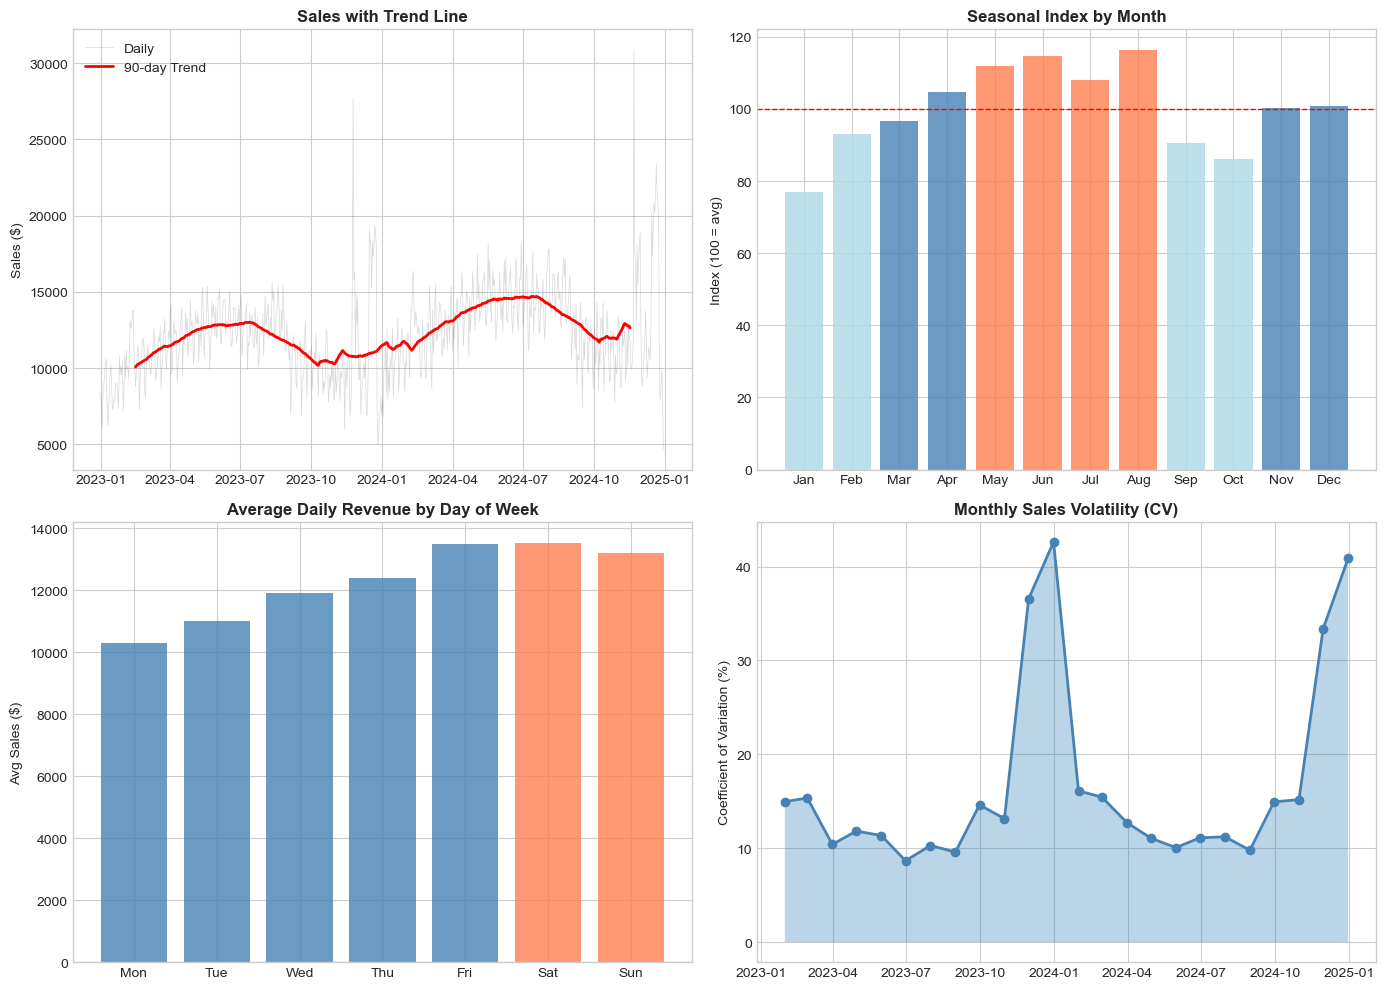

In [83]:
# Comprehensive visualization for the case study
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Full time series with trend
ax1 = axes[0, 0]
ax1.plot(df_trend.index, df_trend['sales'], linewidth=0.5, alpha=0.3, color='gray', label='Daily')
ax1.plot(df_trend.index, df_trend['trend'], linewidth=2, color='red', label='90-day Trend')
ax1.set_title('Sales with Trend Line', fontsize=12, fontweight='bold')
ax1.legend()
ax1.set_ylabel('Sales ($)')

# 2. Seasonal pattern
ax2 = axes[0, 1]
colors = ['coral' if idx > 105 else ('lightblue' if idx < 95 else 'steelblue') 
          for idx in seasonal_index.values]
bars = ax2.bar(seasonal_index.index, seasonal_index.values, color=colors, alpha=0.8)
ax2.axhline(y=100, color='red', linestyle='--', linewidth=1)
ax2.set_title('Seasonal Index by Month', fontsize=12, fontweight='bold')
ax2.set_ylabel('Index (100 = avg)')

# 3. Day of week pattern
ax3 = axes[1, 0]
colors = ['coral' if d in ['Saturday', 'Sunday'] else 'steelblue' for d in dow_order]
ax3.bar(range(7), dow_revenue['Avg Daily Revenue'].values, color=colors, alpha=0.8)
ax3.set_xticks(range(7))
ax3.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
ax3.set_title('Average Daily Revenue by Day of Week', fontsize=12, fontweight='bold')
ax3.set_ylabel('Avg Sales ($)')

# 4. Monthly volatility
ax4 = axes[1, 1]
ax4.plot(monthly_cv.index, monthly_cv.values, marker='o', linewidth=2, color='steelblue')
ax4.fill_between(monthly_cv.index, monthly_cv.values, alpha=0.3)
ax4.set_title('Monthly Sales Volatility (CV)', fontsize=12, fontweight='bold')
ax4.set_ylabel('Coefficient of Variation (%)')

plt.tight_layout()
plt.show()

---

# 9. Live Exercises with Solutions

Complete these exercises to practice time series concepts. Try them yourself first, then check the solutions!

## Exercise 1: Working with Dates (10 min)

**Tasks:**
1. Create a timestamp for your birthday in 2024
2. Calculate how many days until that date from January 1, 2024
3. What day of the week does it fall on?
4. Create a date range for the week of your birthday

In [84]:
# YOUR CODE HERE (Exercise 1)
# Example birthday: March 15

# 1. Create timestamp


# 2. Days from Jan 1


# 3. Day of week


# 4. Week range


In [85]:
# SOLUTION: Exercise 1
print("=== SOLUTION: Exercise 1 ===")

# 1. Create timestamp (using March 15 as example)
birthday = pd.Timestamp('2024-03-15')
print(f"1. Birthday: {birthday}")

# 2. Days from Jan 1
jan1 = pd.Timestamp('2024-01-01')
days_until = (birthday - jan1).days
print(f"2. Days from Jan 1: {days_until}")

# 3. Day of week
print(f"3. Day of week: {birthday.day_name()}")

# 4. Week range (birthday week: 3 days before to 3 days after)
week_start = birthday - pd.Timedelta(days=3)
week_end = birthday + pd.Timedelta(days=3)
birthday_week = pd.date_range(week_start, week_end)
print(f"4. Birthday week: {list(birthday_week.date)}")

=== SOLUTION: Exercise 1 ===
1. Birthday: 2024-03-15 00:00:00
2. Days from Jan 1: 74
3. Day of week: Friday
4. Birthday week: [datetime.date(2024, 3, 12), datetime.date(2024, 3, 13), datetime.date(2024, 3, 14), datetime.date(2024, 3, 15), datetime.date(2024, 3, 16), datetime.date(2024, 3, 17), datetime.date(2024, 3, 18)]


## Exercise 2: Resampling Practice (15 min)

Using our `df_sales` data:
1. Calculate the total sales for each quarter
2. Find the week with the highest total sales
3. Calculate the month-over-month percentage change
4. Find months where sales increased by more than 5% compared to the previous month

In [ ]:
# YOUR CODE HERE (Exercise 2)
df_ts = df_sales.set_index('date')

# 1. Quarterly totals


# 2. Best week


# 3. Month-over-month change


# 4. Months with >5% growth


In [ ]:
# SOLUTION: Exercise 2
print("=== SOLUTION: Exercise 2 ===")
df_ts = df_sales.set_index('date')

# 1. Quarterly totals
quarterly = df_ts['sales'].resample('QE').sum()
print("\n1. Quarterly Sales:")
print(quarterly.round(2))

# 2. Best week
weekly = df_ts['sales'].resample('W').sum()
best_week = weekly.idxmax()
best_week_sales = weekly.max()
print(f"\n2. Best week: {best_week.date()} with ${best_week_sales:,.2f}")

# 3. Month-over-month change
monthly = df_ts['sales'].resample('ME').sum()
mom_change = monthly.pct_change() * 100
print("\n3. Month-over-Month % Change:")
print(mom_change.round(2).head(12))

# 4. Months with >5% growth
growth_months = mom_change[mom_change > 5]
print(f"\n4. Months with >5% growth:")
print(growth_months.round(2))

## Exercise 3: Rolling Statistics (10 min)

Using `df_sales`:
1. Calculate a 14-day moving average
2. Calculate a 14-day rolling standard deviation
3. Create "Bollinger Bands" (MA ± 2 * std)
4. Find days where sales fell below the lower band (unusually low)

In [ ]:
# YOUR CODE HERE (Exercise 3)

# 1. 14-day MA


# 2. 14-day std


# 3. Bollinger Bands


# 4. Days below lower band


In [ ]:
# SOLUTION: Exercise 3
print("=== SOLUTION: Exercise 3 ===")

df_bb = df_ts[['sales']].copy()

# 1. 14-day MA
df_bb['MA_14'] = df_bb['sales'].rolling(window=14).mean()

# 2. 14-day std
df_bb['STD_14'] = df_bb['sales'].rolling(window=14).std()

# 3. Bollinger Bands
df_bb['upper_band'] = df_bb['MA_14'] + 2 * df_bb['STD_14']
df_bb['lower_band'] = df_bb['MA_14'] - 2 * df_bb['STD_14']

# 4. Days below lower band
below_band = df_bb[df_bb['sales'] < df_bb['lower_band']]
print(f"Days with unusually low sales: {len(below_band)}")
print("\nFirst 10 days below lower band:")
print(below_band[['sales', 'lower_band', 'MA_14']].head(10).round(2))

# Visualization
fig, ax = plt.subplots(figsize=(14, 5))
df_sample = df_bb.loc['2024-04':'2024-06']

ax.plot(df_sample.index, df_sample['sales'], linewidth=0.8, alpha=0.6, label='Daily Sales')
ax.plot(df_sample.index, df_sample['MA_14'], linewidth=2, color='orange', label='14-day MA')
ax.fill_between(df_sample.index, df_sample['lower_band'], df_sample['upper_band'], 
                alpha=0.2, color='gray', label='Bollinger Bands')

# Mark days below band
below_sample = below_band.loc['2024-04':'2024-06']
ax.scatter(below_sample.index, below_sample['sales'], color='red', s=50, zorder=5, label='Below Band')

ax.set_title('Sales with Bollinger Bands (Apr-Jun 2024)', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Exercise 4: Business Analysis Challenge (15 min)

Your manager asks you to answer these questions about the sales data:

1. **Weekend Effect**: What is the average difference in sales between weekends and weekdays?
2. **Holiday Impact**: How much higher are November-December sales compared to the yearly average?
3. **Best vs Worst**: What is the ratio of the best month's sales to the worst month's sales?
4. **Growth Consistency**: In how many months did we see positive growth compared to the same month last year?

In [ ]:
# YOUR CODE HERE (Exercise 4)

# 1. Weekend effect


# 2. Holiday impact


# 3. Best vs worst month


# 4. Growth consistency


In [ ]:
# SOLUTION: Exercise 4
print("=== SOLUTION: Exercise 4 ===")
print("\n📊 Business Analysis Report")
print("=" * 50)

# 1. Weekend effect
weekend_avg = df_ts[df_ts['is_weekend']]['sales'].mean()
weekday_avg = df_ts[~df_ts['is_weekend']]['sales'].mean()
weekend_effect = (weekend_avg - weekday_avg) / weekday_avg * 100

print(f"\n1. WEEKEND EFFECT")
print(f"   Weekday average: ${weekday_avg:,.2f}")
print(f"   Weekend average: ${weekend_avg:,.2f}")
print(f"   Weekend premium: +{weekend_effect:.1f}%")

# 2. Holiday impact (Nov-Dec vs rest of year)
holiday_months = df_ts[df_ts['month'].isin([11, 12])]['sales'].mean()
non_holiday = df_ts[~df_ts['month'].isin([11, 12])]['sales'].mean()
holiday_impact = (holiday_months - non_holiday) / non_holiday * 100

print(f"\n2. HOLIDAY IMPACT (Nov-Dec)")
print(f"   Non-holiday average: ${non_holiday:,.2f}")
print(f"   Holiday average: ${holiday_months:,.2f}")
print(f"   Holiday lift: +{holiday_impact:.1f}%")

# 3. Best vs worst month
monthly_totals = df_ts['sales'].resample('ME').sum()
best_month = monthly_totals.idxmax()
worst_month = monthly_totals.idxmin()
ratio = monthly_totals.max() / monthly_totals.min()

print(f"\n3. BEST vs WORST MONTH")
print(f"   Best month: {best_month.strftime('%B %Y')} - ${monthly_totals.max():,.2f}")
print(f"   Worst month: {worst_month.strftime('%B %Y')} - ${monthly_totals.min():,.2f}")
print(f"   Best/Worst ratio: {ratio:.2f}x")

# 4. Growth consistency (2024 vs 2023)
monthly_2023 = df_ts.loc['2023']['sales'].resample('ME').sum()
monthly_2024 = df_ts.loc['2024']['sales'].resample('ME').sum()

# Align by month number for comparison
monthly_2023.index = monthly_2023.index.month
monthly_2024.index = monthly_2024.index.month

yoy_comparison = pd.DataFrame({
    '2023': monthly_2023,
    '2024': monthly_2024
})
yoy_comparison['growth'] = (yoy_comparison['2024'] - yoy_comparison['2023']) / yoy_comparison['2023'] * 100
positive_months = (yoy_comparison['growth'] > 0).sum()

print(f"\n4. YEAR-OVER-YEAR GROWTH CONSISTENCY")
print(f"   Months with positive YoY growth: {positive_months} out of 12")
print(f"   Average YoY growth: {yoy_comparison['growth'].mean():.1f}%")
print("\n   Monthly YoY Growth:")
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
for i, (month, row) in enumerate(yoy_comparison.iterrows()):
    indicator = "✅" if row['growth'] > 0 else "❌"
    print(f"   {months[i]}: {row['growth']:+.1f}% {indicator}")

---

# Summary and Key Takeaways

## What We Covered

| Topic | Key Functions/Concepts |
|-------|------------------------|
| **DateTime Basics** | `pd.Timestamp()`, `pd.to_datetime()`, `pd.Timedelta()` |
| **Date Ranges** | `pd.date_range()`, frequency codes (D, W, ME, QE, YE, H) |
| **Time Indexing** | `.set_index()`, partial string indexing (`df['2024-06']`) |
| **dt Accessor** | `.dt.year`, `.dt.month`, `.dt.dayofweek`, `.dt.day_name()` |
| **Resampling** | `.resample('W').sum()`, `.resample('ME').mean()` |
| **Rolling** | `.rolling(window=7).mean()`, `.ewm(span=30).mean()` |
| **Missing Data** | `.ffill()`, `.bfill()`, `.interpolate()` |
| **Time Zones** | `.tz_localize()`, `.tz_convert()` |

## Best Practices

1. **Always set datetime as index** for time series operations
2. **Use appropriate resampling** - don't aggregate too much (lose detail) or too little (too noisy)
3. **Choose filling methods wisely** - consider the nature of your data
4. **Document time zones** - always know if your data is UTC, local, or naive
5. **Visualize at multiple scales** - daily, weekly, monthly views reveal different patterns

## Next Steps

To deepen your time series skills:
- **Forecasting**: Learn `statsmodels` for ARIMA, exponential smoothing
- **Advanced decomposition**: Separate trend, seasonal, and residual components
- **Machine learning**: Apply sklearn or deep learning for time series prediction
- **Real-time data**: Work with streaming data using pandas with APIs

---

## Quick Reference: Frequency Codes

```
D   = Calendar day              B   = Business day
W   = Weekly                    ME  = Month end
MS  = Month start               QE  = Quarter end
QS  = Quarter start             YE  = Year end
YS  = Year start                H   = Hourly
T/min = Minute                  S   = Second
2H  = Every 2 hours             3D  = Every 3 days
```

---

**Congratulations!** You've completed the Pandas Time Series module. 🎉